# Explainable AI for Autonomous Vehicle Safety

## Project Overview
This project explores whether machine learning can help identify higher-risk autonomous vehicle safety events using historical disengagement and collision reports. The analysis uses data from the California DMV to examine patterns in autonomous vehicle disengagements, testing mileage, and reported collisions.

The goal is to build an initial classification model that can distinguish between disengagement and collision events and evaluate whether the available data contains useful patterns for identifying higher-risk safety events.

### Research Question

Can machine learning models identify patterns in historical autonomous vehicle disengagement and collision reports and distinguish between these two types of reported events?

For this project, I used publicly available 2024 California Department of Motor Vehicles (DMV) disengagement and collision reports to explore whether machine learning could identify differences between the two categories.

I compared several classification models, including Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, and Neural Networks. I also explored model optimization to see whether tuning could improve performance.

Since collision reports were much less common than disengagement reports, I focused on precision, recall, and F1-score rather than accuracy alone.

The goal of this project is to understand patterns in historical reporting data. The models do not predict future collisions or determine whether a particular autonomous vehicle or manufacturer is safe.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Collection and Loading

The project uses three datasets from the California DMV: autonomous vehicle disengagement reports, autonomous mileage reports, and autonomous vehicle collision reports. These datasets provide information about disengagement events, testing mileage, manufacturers, and reported collisions.

In [2]:
disengagement_df = pd.read_csv("2024-Autonomous-Vehicle-Disengagement-Reports-CSV-1.csv",encoding="cp1252")
disengagement_df.head()

,Manufacturer,Permit Number,DATE,VIN NUMBER,VEHICLE IS CAPABLE OF OPERATING WITHOUT A DRIVER\n(Yes or No),DRIVER PRESENT\n(Yes or No),"DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)","DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)",DESCRIPTION OF FACTS CAUSING DISENGAGEMENT
0,aiMotive Inc.,AVT036,11/21/2024,4T1B21HK3KU514477,No,Yes,Test Driver,Street,Safety Driver disengaged autonomous mode to en...
1,aiMotive Inc.,AVT036,11/21/2024,4T1B21HK3KU514477,No,Yes,Test Driver,Street,Safety Driver disengaged autonomous mode due t...
2,aiMotive Inc.,AVT036,11/21/2024,4T1B21HK3KU514477,No,Yes,Test Driver,Freeway,Safety Driver disengaged autonomous mode to pe...
3,aiMotive Inc.,AVT036,10/2/2024,4T1B21HK6KU514747,No,Yes,Test Driver,Street,Safety Driver disengaged autonomous mode upon ...
4,aiMotive Inc.,AVT036,9/27/2024,4T1B21HK6KU514747,No,Yes,Test Driver,Highway,Safety Driver disengaged autonomous mode upon ...


In [3]:
mileage_df = pd.read_csv("2024-Autonomous-Mileage-Reports-CSV-2.csv")

mileage_df.head()

,Manufacturer,Permit Number,VIN NUMBER,Annual Total of Disengagements,DEC 2023,JAN 2024,FEB 2024,MAR 2024,APR 2024,MAY 2024,...,AUG 2024,SEP 2024,OCT 2024,NOV 2024,ANNUAL TOTAL,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21
0,aiMotive Inc.,AVT036,4T1B21HK3KU514477,75,485.01,526.06,601.46,142.53,27.51,0.19,...,0.0,64.20,11.19,22.22,"1,880.37",NaN,NaN,NaN,NaN,NaN
1,aiMotive Inc.,AVT036,1C4RJYB64P8914902,68,5.48,332.43,0.00,185.78,445.60,78.01,...,0.0,46.64,50.26,105.67,"1,249.98",NaN,NaN,NaN,NaN,NaN
2,aiMotive Inc.,AVT036,4T1B21HK6KU514747,45,170.80,71.61,0.00,0.00,15.34,0.00,...,0.0,205.33,151.10,0.00,614.18,NaN,NaN,NaN,NaN,NaN
3,Apollo,AVT015,3LN6L5LU2HR615153,0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.0,0.00,0.00,0.00,0,NaN,NaN,NaN,NaN,NaN
4,Apollo,AVT015,2C4RC1N77LR190366,0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.0,0.00,0.00,0.00,0,NaN,NaN,NaN,NaN,NaN


In [4]:
collision_df = pd.read_excel("DMV AV Testing Collisions Data.xlsx")
collision_df.head()

,_Moving__V1_or_V2_or_Both_,_Stopped__V1_or_V2_,# of Vehicles involved,Backing,Broadside,City,Clear,Cloudy,Construction,County,...,V1_Vehicle Model,V1_Vehicle Year,V2 Damage _minor_ moderate_ severe_,V2_OPV Make,V2_OPV Model,V2_OPV Year,Wet,Wind,Year,Zip
0,V2,V1,2.0,NaN,V2,Palo Alto,NaN,NaN,NaN,Santa Clara,...,SQ5,2014,NaN,Honda,Civic,2012.0,NaN,NaN,2014,94303
1,Both,NaN,2.0,NaN,V2,Mountain View,NaN,NaN,NaN,Santa Clara,...,RX450H,2012,NaN,Audi,S6,2015.0,NaN,NaN,2015,94040
2,NaN,NaN,2.0,NaN,NaN,Mountain View,NaN,NaN,NaN,Santa Clara,...,RX450H,2011,NONE,BMW,3 Series,2011.0,NaN,NaN,2015,94040
3,NaN,V1,2.0,NaN,NaN,Mountain View,NaN,NaN,NaN,Santa Clara,...,RX450H,2012,NONE,Toyota,Camry,2000.0,NaN,NaN,2015,94043
4,NaN,V1,2.0,NaN,NaN,Mountain View,NaN,NaN,NaN,Santa Clara,...,RX450H,2011,NONE,Ford,Expedition,2003.0,NaN,NaN,2015,94041


## Data Cleaning

Before performing the analysis, the datasets were examined for missing values, duplicate records, inconsistent data formats, and data type issues. Blank rows and completely empty columns were removed where appropriate. Date and numeric fields were converted to suitable formats, and inconsistent categorical values were standardized.

Potential duplicate disengagement records were reviewed but retained because the dataset does not contain a unique event identifier or event time that would confirm whether the records represent true duplicates or separate disengagement events.

In [5]:
print("Disengagement:", disengagement_df.shape)
print("Mileage:", mileage_df.shape)
print("Collision:", collision_df.shape)

Disengagement: (12607, 9)
Mileage: (2819, 22)
Collision: (983, 69)


In [6]:
print("DISENGAGEMENT")
print("Duplicate rows:", disengagement_df.duplicated().sum())
print(disengagement_df.isnull().sum())

print("\nMILEAGE")
print("Duplicate rows:", mileage_df.duplicated().sum())
print(mileage_df.isnull().sum())

print("\nCOLLISION")
print("Duplicate rows:", collision_df.duplicated().sum())
print(collision_df.isnull().sum())

DISENGAGEMENT
Duplicate rows: 11335
Manufacturer                                                                                        10834
Permit Number                                                                                       10834
DATE                                                                                                10834
VIN NUMBER                                                                                          10834
VEHICLE IS CAPABLE OF OPERATING WITHOUT A DRIVER\n(Yes or No)                                       10834
DRIVER PRESENT\n(Yes or No)                                                                         10834
DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)                 10834
DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)    10834
DESCRIPTION OF FACTS CAUSING DISENGAGEMENT                                                          10834
dtype: int

In [7]:
# Remove completely empty rows
disengagement_df = disengagement_df.dropna(how="all")

# Remove completely empty rows from mileage data
mileage_df = mileage_df.dropna(how="all")

# Remove completely empty columns from mileage data
mileage_df = mileage_df.dropna(axis=1, how="all")

# Check the new shapes
print("Disengagement:", disengagement_df.shape)
print("Mileage:", mileage_df.shape)
print("Collision:", collision_df.shape)

# Check duplicates again
print("\nDisengagement duplicates:", disengagement_df.duplicated().sum())
print("Mileage duplicates:", mileage_df.duplicated().sum())
print("Collision duplicates:", collision_df.duplicated().sum())

Disengagement: (1773, 9)
Mileage: (2819, 17)
Collision: (983, 69)

Disengagement duplicates: 502
Mileage duplicates: 0
Collision duplicates: 0


In [8]:
duplicate_rows = disengagement_df[disengagement_df.duplicated(keep=False)]

duplicate_rows.sort_values(by=["Manufacturer", "DATE"]).head(20)

,Manufacturer,Permit Number,DATE,VIN NUMBER,VEHICLE IS CAPABLE OF OPERATING WITHOUT A DRIVER\n(Yes or No),DRIVER PRESENT\n(Yes or No),"DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)","DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)",DESCRIPTION OF FACTS CAUSING DISENGAGEMENT
329,Apple Inc.,AVT030,1/24/2024,2T2BGMCA0HC019225,No,Yes,Test Driver,Interstate,The ADS incorrectly predicted the behavior of ...
330,Apple Inc.,AVT030,1/24/2024,2T2BGMCA0HC019225,No,Yes,Test Driver,Interstate,The ADS incorrectly predicted the behavior of ...
336,Apple Inc.,AVT030,1/24/2024,2T2BGMCA9GC007394,No,Yes,AV System,Freeway,The ADS initiated a disengagement due to a dia...
337,Apple Inc.,AVT030,1/24/2024,2T2BGMCA9GC007394,No,Yes,AV System,Freeway,The ADS initiated a disengagement due to a dia...
338,Apple Inc.,AVT030,1/24/2024,2T2BGMCA9GC007394,No,Yes,AV System,Freeway,The ADS initiated a disengagement due to a dia...
307,Apple Inc.,AVT030,1/26/2024,2T2BGMCA3GC007911,No,Yes,Test Driver,Freeway,The ADS incorrectly predicted the behavior of ...
308,Apple Inc.,AVT030,1/26/2024,2T2BGMCA3GC007911,No,Yes,Test Driver,Freeway,The ADS incorrectly predicted the behavior of ...
309,Apple Inc.,AVT030,1/26/2024,2T2BGMCA0HC019225,No,Yes,Test Driver,Freeway,The ADS incorrectly predicted the behavior of ...
310,Apple Inc.,AVT030,1/26/2024,2T2BGMCA0HC019225,No,Yes,Test Driver,Freeway,The ADS incorrectly predicted the behavior of ...
311,Apple Inc.,AVT030,1/26/2024,2T2BGMCA0HC019225,No,Yes,Test Driver,Freeway,The ADS incorrectly predicted the behavior of ...


In [9]:
disengagement_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1773 entries, 0 to 1772
Data columns (total 9 columns):
 #   Column                                                                                          Non-Null Count  Dtype 
---  ------                                                                                          --------------  ----- 
 0   Manufacturer                                                                                    1773 non-null   object
 1   Permit Number                                                                                   1773 non-null   object
 2   DATE                                                                                            1773 non-null   object
 3   VIN NUMBER                                                                                      1773 non-null   object
 4   VEHICLE IS CAPABLE OF OPERATING WITHOUT A DRIVER
(Yes or No)                                    1773 non-null   object
 5   DRIVER PRESENT
(Yes or No)

In [10]:
mileage_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2819 entries, 0 to 2818
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Manufacturer                    2819 non-null   object 
 1   Permit Number                   2819 non-null   object 
 2   VIN NUMBER                      2819 non-null   object 
 3   Annual Total of Disengagements  2819 non-null   int64  
 4   DEC 2023                        2819 non-null   float64
 5   JAN 2024                        2819 non-null   float64
 6   FEB 2024                        2819 non-null   float64
 7   MAR 2024                        2819 non-null   float64
 8   APR 2024                        2817 non-null   float64
 9   MAY 2024                        2817 non-null   float64
 10  JUN 2024                        2817 non-null   float64
 11  JULY 2024                       2817 non-null   float64
 12  AUG 2024                        28

In [11]:
collision_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 983 entries, 0 to 982
Data columns (total 69 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   _Moving__V1_or_V2_or_Both_             661 non-null    object 
 1   _Stopped__V1_or_V2_                    445 non-null    object 
 2   # of Vehicles involved                 982 non-null    float64
 3   Backing                                98 non-null     object 
 4   Broadside                              84 non-null     object 
 5   City                                   983 non-null    object 
 6   Clear                                  773 non-null    object 
 7   Cloudy                                 94 non-null     object 
 8   Construction                           6 non-null      object 
 9   County                                 983 non-null    object 
 10  Dark_No Street Lights                  11 non-null     object 
 11  Dark_S

In [12]:
disengagement_df['DATE'] = pd.to_datetime(disengagement_df['DATE'],format='mixed')

In [13]:
disengagement_df['DATE'].dtype

dtype('<M8[ns]')

In [14]:
disengagement_df['DATE'].min(), disengagement_df['DATE'].max()

(Timestamp('2023-12-01 00:00:00'), Timestamp('2024-12-03 00:00:00'))

In [15]:
mileage_df['ANNUAL TOTAL'].head(10)

0    1,880.37
1    1,249.98
2      614.18
3           0
4           0
5           0
6           0
7           0
8         3.1
9      2000.7
Name: ANNUAL TOTAL, dtype: object

In [16]:
mileage_df['ANNUAL TOTAL'] = mileage_df['ANNUAL TOTAL'].str.replace(',', '')
mileage_df['ANNUAL TOTAL'] = pd.to_numeric(mileage_df['ANNUAL TOTAL'])

In [17]:
mileage_df['ANNUAL TOTAL'].dtype

dtype('float64')

In [18]:
mileage_df[mileage_df.isnull().any(axis=1)]

,Manufacturer,Permit Number,VIN NUMBER,Annual Total of Disengagements,DEC 2023,JAN 2024,FEB 2024,MAR 2024,APR 2024,MAY 2024,JUN 2024,JULY 2024,AUG 2024,SEP 2024,OCT 2024,NOV 2024,ANNUAL TOTAL
120,BOSCH,AVT006,WDD2221591A470497,4,0.00,19.96,0.0,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19.96
121,BOSCH,AVT006,WDD2221591A470796,73,34.98,57.89,46.4,4.98,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,144.25


## Exploratory Data Analysis

Exploratory data analysis was performed to understand patterns in the disengagement, mileage, and collision datasets. The analysis examines disengagements across manufacturers, locations, initiators, and time periods. Autonomous mileage is also considered to provide context for disengagement counts.

The collision data is explored to understand manufacturer patterns, injury reports, common collision types, vehicle operating modes, and changes in reported collisions over time.

In [19]:
disengagement_df['Manufacturer'].value_counts()

Manufacturer
Ghost Autonomy Inc.                                         351
Motional AD Inc.                                            320
Apple Inc.                                                  285
Waymo LLC                                                   244
aiMotive Inc.                                               188
IMAGRY                                                      136
NURO, INC.                                                  103
BOSCH                                                        77
Zoox, Inc.                                                   34
Valeo North America Inc.                                     12
Nissan North America. INC DBA NATC-SV                        11
MERCEDES-BENZ RESEARCH & DEVELOPMENT NORTH AMERICA, INC.      4
PONY.AI, INC.                                                 3
Weride Corp                                                   3
Cruise LLC                                                    1
Gatik AI, Inc.             

### Disengagement Analysis

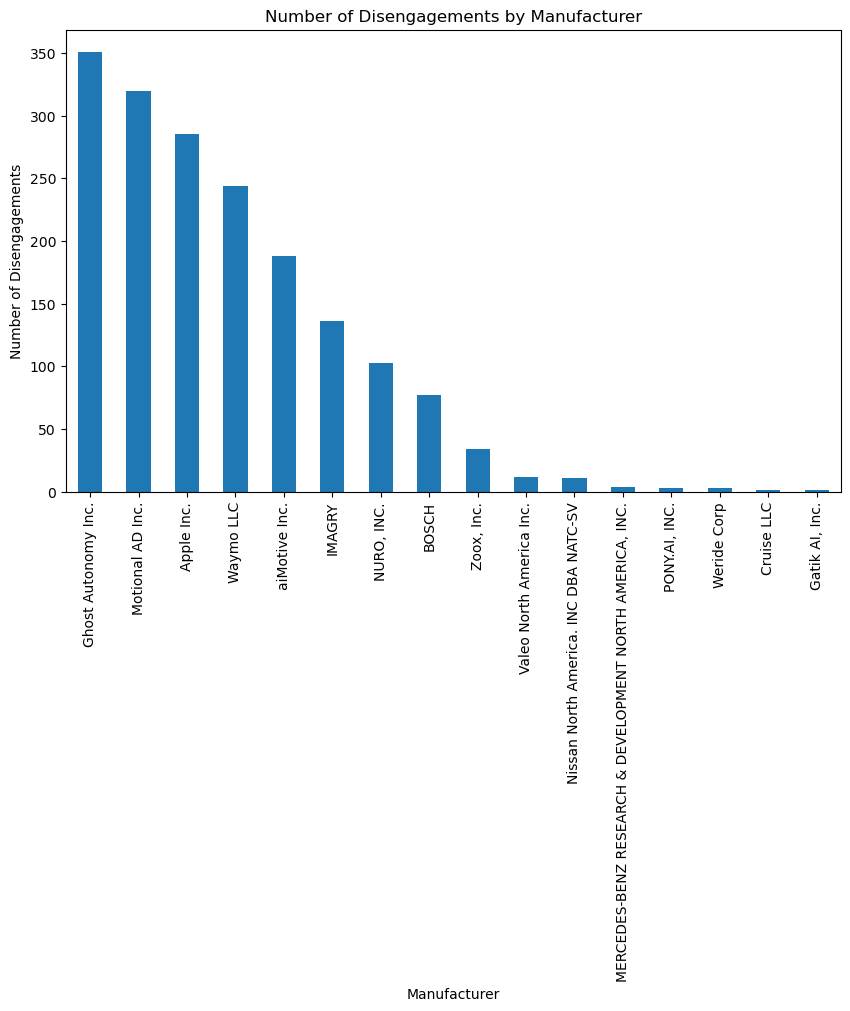

In [20]:
plt.figure(figsize=(10, 6))

disengagement_df['Manufacturer'].value_counts().plot(kind='bar')

plt.title('Number of Disengagements by Manufacturer')
plt.xlabel('Manufacturer')
plt.ylabel('Number of Disengagements')
plt.xticks(rotation=90)

plt.show()

Observation: The number of reported disengagements varies across the companies participating in autonomous vehicle testing. Ghost Autonomy, Motional AD, Apple, and Waymo have the highest number of reported disengagement events in this dataset. However, these numbers should not be directly used to compare safety because each company may have completed a different amount of autonomous testing and mileage.

In [21]:
disengagement_df['DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)'].value_counts()

DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)
Street              949
Highway             373
Freeway             248
Interstate          178
Urban                12
STREET               11
Parking Facility      2
Name: count, dtype: int64

In [22]:
disengagement_df['DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)'] = \
disengagement_df['DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)'].str.title()

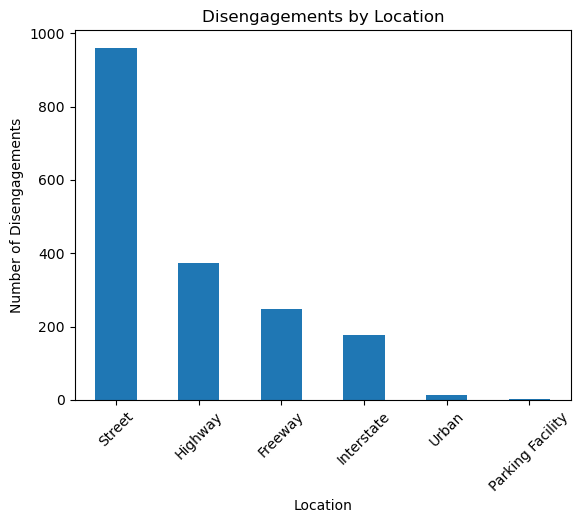

In [23]:
disengagement_df['DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)'].value_counts().plot(kind='bar')

plt.title('Disengagements by Location')
plt.xlabel('Location')
plt.ylabel('Number of Disengagements')
plt.xticks(rotation=45)

plt.show()

In [24]:
disengagement_df['DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)'] = \
disengagement_df['DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)'].str.title()

In [25]:
disengagement_df['DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)'].value_counts()

DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)
Test Driver    1606
Av System       164
Operator          3
Name: count, dtype: int64

In [26]:
disengagement_df['DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)'] = \
disengagement_df['DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)'].replace('Av System', 'AV System')

In [27]:
disengagement_df['DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)'].value_counts()

DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)
Test Driver    1606
AV System       164
Operator          3
Name: count, dtype: int64

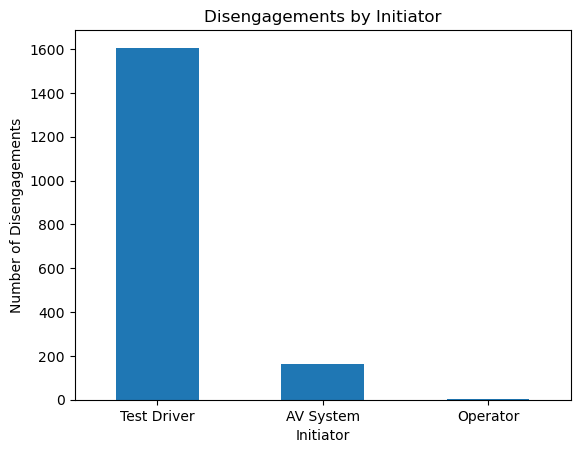

In [28]:
disengagement_df['DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)'].value_counts().plot(kind='bar')

plt.title('Disengagements by Initiator')
plt.xlabel('Initiator')
plt.ylabel('Number of Disengagements')
plt.xticks(rotation=0)

plt.show()

In [29]:
disengagement_df['Month'] = disengagement_df['DATE'].dt.to_period('M')
disengagement_df['Month'].value_counts().sort_index()

Month
2023-12    316
2024-01    429
2024-02    287
2024-03    148
2024-04    235
2024-05    113
2024-06     43
2024-07     20
2024-08     34
2024-09     63
2024-10     52
2024-11     32
2024-12      1
Freq: M, Name: count, dtype: int64

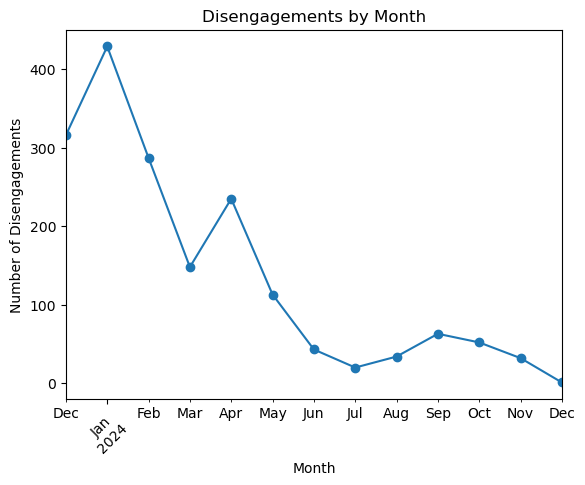

In [30]:
monthly_disengagements = disengagement_df['Month'].value_counts().sort_index()

monthly_disengagements.plot(kind='line', marker='o')

plt.title('Disengagements by Month')
plt.xlabel('Month')
plt.ylabel('Number of Disengagements')
plt.xticks(rotation=45)

plt.show()

### Mileage and Disengagement Rate Analysis

In [31]:
mileage_by_manufacturer = mileage_df.groupby('Manufacturer')['ANNUAL TOTAL'].sum()

mileage_by_manufacturer.sort_values(ascending=False)

Manufacturer
Waymo LLC                                                   2.389565e+06
Zoox, Inc.                                                  9.518710e+05
NURO, INC.                                                  2.105444e+05
Apple Inc.                                                  1.529237e+05
Weride Corp                                                 6.019174e+04
PONY.AI, INC.                                               5.155558e+04
MERCEDES-BENZ RESEARCH & DEVELOPMENT NORTH AMERICA, INC.    4.508121e+04
Motional AD Inc.                                            1.408350e+04
Ghost Autonomy Inc.                                         1.313823e+04
Cruise LLC                                                  8.008010e+03
AutoX Technologies, Inc.                                    7.459000e+03
aiMotive Inc.                                               3.744530e+03
Nissan North America. INC DBA NATC-SV                       2.153000e+03
IMAGRY                                

In [32]:
disengagement_counts = disengagement_df.groupby('Manufacturer').size()

disengagement_counts

Manufacturer
Apple Inc.                                                  285
BOSCH                                                        77
Cruise LLC                                                    1
Gatik AI, Inc.                                                1
Ghost Autonomy Inc.                                         351
IMAGRY                                                      136
MERCEDES-BENZ RESEARCH & DEVELOPMENT NORTH AMERICA, INC.      4
Motional AD Inc.                                            320
NURO, INC.                                                  103
Nissan North America. INC DBA NATC-SV                        11
PONY.AI, INC.                                                 3
Valeo North America Inc.                                     12
Waymo LLC                                                   244
Weride Corp                                                   3
Zoox, Inc.                                                   34
aiMotive Inc.              

In [33]:
manufacturer_data = pd.concat([disengagement_counts, mileage_by_manufacturer],axis=1)
manufacturer_data.columns = ['Disengagements', 'Miles']
manufacturer_data

,Disengagements,Miles
Manufacturer,,
Apple Inc.,285.0,1.529237e+05
BOSCH,77.0,1.642100e+02
Cruise LLC,1.0,8.008010e+03
"Gatik AI, Inc.",1.0,7.260000e+02
Ghost Autonomy Inc.,351.0,1.313823e+04
IMAGRY,136.0,8.562000e+02
"MERCEDES-BENZ RESEARCH & DEVELOPMENT NORTH AMERICA, INC.",4.0,4.508121e+04
Motional AD Inc.,320.0,1.408350e+04
"NURO, INC.",103.0,2.105444e+05


In [34]:
manufacturer_data = manufacturer_data.dropna().copy()
manufacturer_data['Disengagements_per_1000_miles'] = (manufacturer_data['Disengagements'] / manufacturer_data['Miles']) * 1000
manufacturer_data.sort_values('Disengagements_per_1000_miles',ascending=False)

,Disengagements,Miles,Disengagements_per_1000_miles
Manufacturer,,,
BOSCH,77.0,1.642100e+02,468.911759
Valeo North America Inc.,12.0,3.600000e+01,333.333333
IMAGRY,136.0,8.562000e+02,158.841392
aiMotive Inc.,188.0,3.744530e+03,50.206568
Ghost Autonomy Inc.,351.0,1.313823e+04,26.715927
Motional AD Inc.,320.0,1.408350e+04,22.721625
Nissan North America. INC DBA NATC-SV,11.0,2.153000e+03,5.109150
Apple Inc.,285.0,1.529237e+05,1.863674
"Gatik AI, Inc.",1.0,7.260000e+02,1.377410


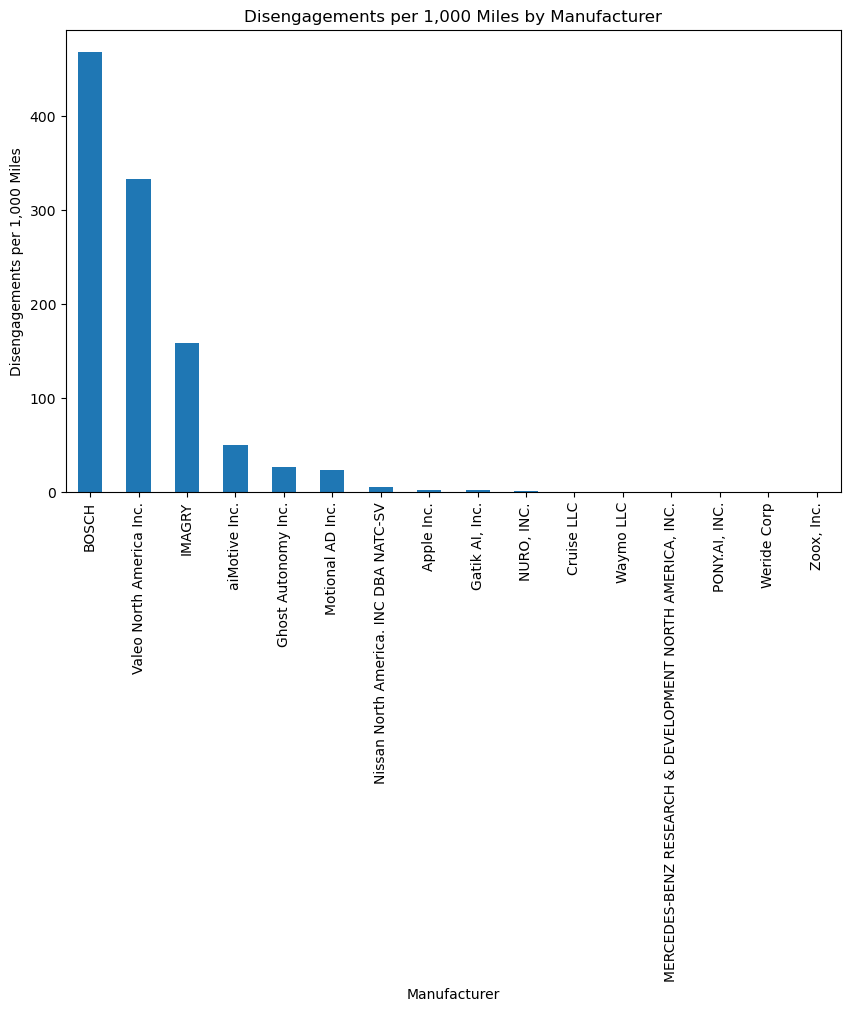

In [35]:
manufacturer_data['Disengagements_per_1000_miles'].sort_values(ascending=False).plot(kind='bar', figsize=(10, 6))
plt.title('Disengagements per 1,000 Miles by Manufacturer')
plt.xlabel('Manufacturer')
plt.ylabel('Disengagements per 1,000 Miles')
plt.xticks(rotation=90)
plt.show()

Observation: Disengagement rates vary significantly across manufacturers after adjusting for autonomous miles driven. Some manufacturers, such as BOSCH and Valeo, show very high rates because they reported relatively low testing mileage. Therefore, these rates should be interpreted carefully and should not be considered a direct measure of vehicle safety.

### Collision Analysis

In [36]:
collision_df['V1_Manufacturer'] = (collision_df['V1_Manufacturer'].str.strip().str.upper())
collision_df['V1_Manufacturer'].value_counts()

V1_Manufacturer
WAYMO LLC                            438
ZOOX INC                             167
CRUISE LLC                           138
GM CRUISE                            100
APPLE INC                             23
GOOGLE                                21
PONY.AI                               15
WERIDE CORP DBA WERIDE AI             12
NURO, INC                             10
MERC BENZ                              9
LYFT, INC                              8
AURORA INNOVATION                      4
WAYMO                                  4
ARGO AI, LLC                           4
GHOST AUTONOMY INC                     3
APOLLO AUTONOMOUS DRIVING USA LLC      3
WERIDE CORP                            2
MERCEDES-BENZ                          2
UATC, LLC (UBER)                       2
WOVEN BY TOYOTA                        1
MAY MOBILITY                           1
BEEP INC                               1
AUTOX TECHNOLOGIES INC                 1
OHMIO, INC                             1


In [37]:
collision_df['V1_Manufacturer'] = collision_df['V1_Manufacturer'].replace({
    'WAYMO': 'WAYMO LLC',
    
    'ZOOX': 'ZOOX INC',
    
    'GM CRUISE': 'CRUISE LLC',
    'CRUISE': 'CRUISE LLC',
    'CRUISE AUTOMATION': 'CRUISE LLC',
    
    'WERIDE CORP': 'WERIDE CORP DBA WERIDE AI',
    
    'MERC BENZ': 'MERCEDES-BENZ',
    
    'AIMOTIVE INC': 'AIMOTIVE',
    
    'MOTIONAL': 'MOTIONAL AD INC'
})

collision_df['V1_Manufacturer'].value_counts()

V1_Manufacturer
WAYMO LLC                            442
CRUISE LLC                           240
ZOOX INC                             168
APPLE INC                             23
GOOGLE                                21
PONY.AI                               15
WERIDE CORP DBA WERIDE AI             14
MERCEDES-BENZ                         11
NURO, INC                             10
LYFT, INC                              8
ARGO AI, LLC                           4
AURORA INNOVATION                      4
APOLLO AUTONOMOUS DRIVING USA LLC      3
GHOST AUTONOMY INC                     3
UATC, LLC (UBER)                       2
WOVEN BY TOYOTA                        1
MAY MOBILITY                           1
AUTOX TECHNOLOGIES INC                 1
BEEP INC                               1
OHMIO, INC                             1
DELPHI                                 1
AIMOTIVE                               1
WOVEN PLANET NORTH AMERICA, INC        1
MOTIONAL AD INC                        1


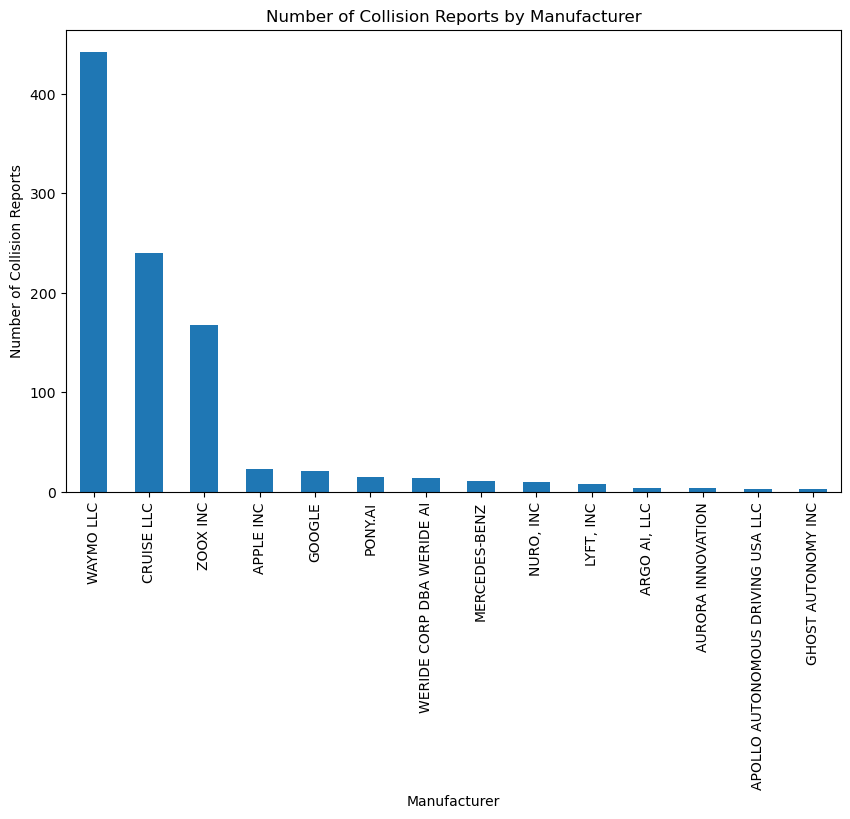

In [38]:
collision_counts = collision_df['V1_Manufacturer'].value_counts()
collision_counts[collision_counts >= 3].plot(kind='bar',figsize=(10, 6))

plt.title('Number of Collision Reports by Manufacturer')
plt.xlabel('Manufacturer')
plt.ylabel('Number of Collision Reports')
plt.xticks(rotation=90)

plt.show()

Observation: Waymo, Cruise, and Zoox have the highest number of collision reports in the dataset. However, collision counts alone should not be interpreted as a direct measure of safety because manufacturers may differ in testing mileage, number of vehicles, and years of operation.

In [39]:
collision_df['Injury'].value_counts(dropna=False)

Injury
NaN    878
X      105
Name: count, dtype: int64

In [40]:
collision_df['Injury_Status'] = collision_df['Injury'].apply(lambda x: 'Yes' if x == 'X' else 'No')
collision_df['Injury_Status'].value_counts()

Injury_Status
No     878
Yes    105
Name: count, dtype: int64

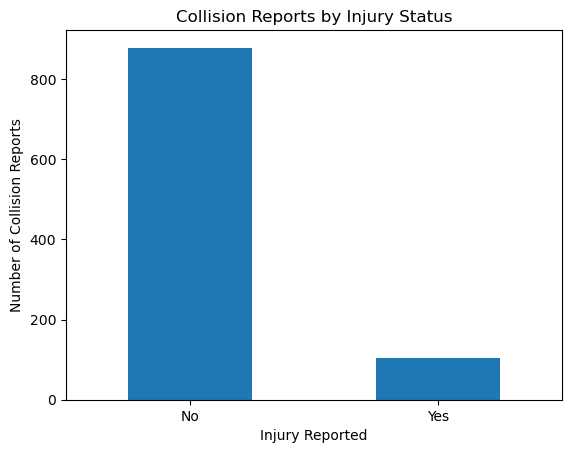

In [41]:
collision_df['Injury_Status'].value_counts().plot(kind='bar')

plt.title('Collision Reports by Injury Status')
plt.xlabel('Injury Reported')
plt.ylabel('Number of Collision Reports')
plt.xticks(rotation=0)

plt.show()

In [42]:
collision_df['Property Damage'].value_counts(dropna=False)

Property Damage
NaN    974
X        9
Name: count, dtype: int64

In [43]:
collision_df['Property_Damage_Status'] = collision_df['Property Damage'].apply(lambda x: 'Yes' if x == 'X' else 'No')
collision_df['Property_Damage_Status'].value_counts()

Property_Damage_Status
No     974
Yes      9
Name: count, dtype: int64

In [44]:
collision_df['Rear_End'].value_counts(dropna=False)

Rear_End
NaN             531
V2              344
V1               87
Both             16
Bicyclist         3
V2&V3             1
Skateboarder      1
Name: count, dtype: int64

In [45]:
collision_df['Side_Swipe'].value_counts(dropna=False)

Side_Swipe
NaN          703
V2           142
Both          91
V1            45
V2 & V3        1
Bicyclist      1
Name: count, dtype: int64

In [46]:
collision_df['Broadside'].value_counts(dropna=False)

Broadside
NaN          899
V2            55
V1            21
Both           7
Bicyclist      1
Name: count, dtype: int64

In [47]:
collision_df['Rear_End_Flag'] = collision_df['Rear_End'].notna().astype(int)
collision_df['Side_Swipe_Flag'] = collision_df['Side_Swipe'].notna().astype(int)
collision_df['Broadside_Flag'] = collision_df['Broadside'].notna().astype(int)

collision_df[
    ['Rear_End_Flag', 'Side_Swipe_Flag', 'Broadside_Flag']].sum()

Rear_End_Flag      452
Side_Swipe_Flag    280
Broadside_Flag      84
dtype: int64

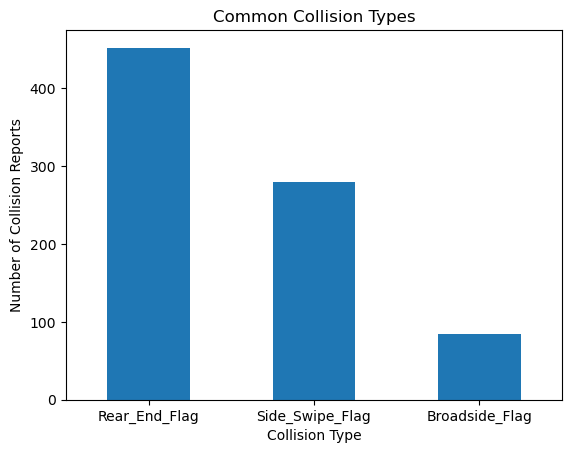

In [48]:
collision_types = collision_df[
    ['Rear_End_Flag', 'Side_Swipe_Flag', 'Broadside_Flag']
].sum()

collision_types.plot(kind='bar')

plt.title('Common Collision Types')
plt.xlabel('Collision Type')
plt.ylabel('Number of Collision Reports')
plt.xticks(rotation=0)

plt.show()

Observation: Rear-end collisions are the most common among the three collision types examined, followed by side-swipe and broadside collisions. This suggests that rear-end interactions are a frequent type of reported collision in the dataset.

In [49]:
collision_df['V1_Mode_Reported_at_Time_of_Collision'].value_counts(dropna=False)

V1_Mode_Reported_at_Time_of_Collision
AM            578
CM            382
A              10
C               7
NaN             4
Autonomous      1
AV              1
Name: count, dtype: int64

In [50]:
collision_df['Operating_Mode'] = collision_df['V1_Mode_Reported_at_Time_of_Collision'].replace({
    'AM': 'Autonomous',
    'A': 'Autonomous',
    'Autonomous': 'Autonomous',
    'AV': 'Autonomous',
    'CM': 'Conventional',
    'C': 'Conventional'
})

collision_df['Operating_Mode'].value_counts(dropna=False)

Operating_Mode
Autonomous      590
Conventional    389
NaN               4
Name: count, dtype: int64

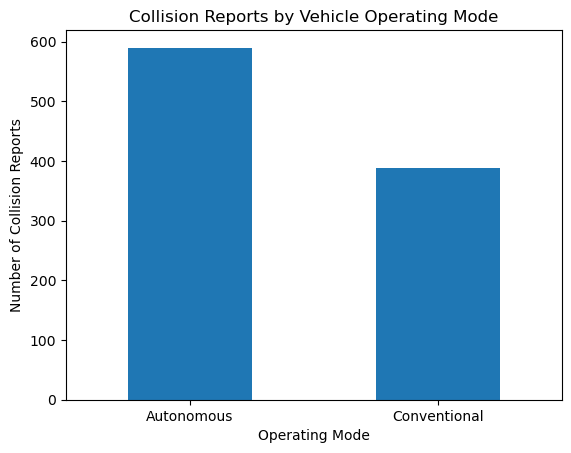

In [51]:
collision_df['Operating_Mode'].value_counts().plot(kind='bar')

plt.title('Collision Reports by Vehicle Operating Mode')
plt.xlabel('Operating Mode')
plt.ylabel('Number of Collision Reports')
plt.xticks(rotation=0)

plt.show()

Observation: More collision reports occurred while vehicles were operating in autonomous mode than in conventional mode. Of the records with known operating mode, 590 occurred in autonomous mode and 389 in conventional mode. However, these counts alone do not indicate that autonomous mode is less safe because the dataset does not show the total mileage or driving time in each operating mode.

## Outlier and Anomaly Analysis

The datasets were also reviewed for unusual or potentially incorrect values. I checked the numeric and categorical variables for values that were outside the expected range or noticeably different from the rest of the data.

In [52]:
collision_df['Year'].value_counts().sort_index()

Year
2014       1
2015      10
2016      14
2017      31
2018      73
2019     105
2020      44
2021     117
2022     150
2023     132
2024     101
2025     136
2026      68
20255      1
Name: count, dtype: int64

In [53]:
collision_df.loc[collision_df['Year'] == 20255, 'Year'] = 2025

In [54]:
collision_df['Year'].value_counts().sort_index()

Year
2014      1
2015     10
2016     14
2017     31
2018     73
2019    105
2020     44
2021    117
2022    150
2023    132
2024    101
2025    137
2026     68
Name: count, dtype: int64

One incorrect year value of 20255 was identified in the collision data. Based on the surrounding record, this was treated as a data-entry error and corrected to 2025. After the correction, the year values were checked again to confirm that they were within the expected reporting period.

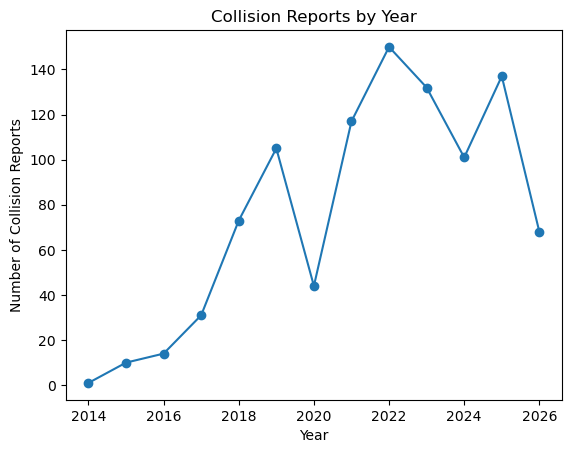

In [55]:
collision_by_year = collision_df['Year'].value_counts().sort_index()

collision_by_year.plot(kind='line', marker='o')

plt.title('Collision Reports by Year')
plt.xlabel('Year')
plt.ylabel('Number of Collision Reports')

plt.show()


Observation: Collision reports generally increased over the reporting period, although the number varies from year to year. The highest number of reports occurred in 2022, followed by another increase in 2025. These counts should be interpreted carefully because changes may reflect differences in testing activity and mileage, and the most recent year may contain incomplete data.

## Preparing Data for Modeling

In [56]:
disengagement_df['Risk_Event'] = 0
collision_df['Risk_Event'] = 1

In [57]:
print(disengagement_df['Risk_Event'].value_counts())
print(collision_df['Risk_Event'].value_counts())

Risk_Event
0    1773
Name: count, dtype: int64
Risk_Event
1    983
Name: count, dtype: int64


In [58]:
print("Disengagement Columns:")
print(disengagement_df.columns.tolist())

print("\nCollision Columns:")
print(collision_df.columns.tolist())

Disengagement Columns:
['Manufacturer', 'Permit Number', 'DATE', 'VIN NUMBER', 'VEHICLE IS CAPABLE OF OPERATING WITHOUT A DRIVER\n(Yes or No)', 'DRIVER PRESENT\n(Yes or No)', 'DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)', 'DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)', 'DESCRIPTION OF FACTS CAUSING DISENGAGEMENT', 'Month', 'Risk_Event']

Collision Columns:
['_Moving__V1_or_V2_or_Both_', '_Stopped__V1_or_V2_', '# of Vehicles involved', 'Backing', 'Broadside', 'City', 'Clear', 'Cloudy', 'Construction', 'County', 'Dark_No Street Lights', 'Dark_Street Lights', 'Day', 'Daylight', 'Dry', 'Dusk_Dawn', 'Entering_Traffic', 'First Street Name', 'First Street Suffix', 'Fog_Visability', 'Head On', 'Hit_Object', 'Injury', 'Involved', 'Lane_Change', 'Left_Turn_', 'Loose material', 'Merging', 'Month', 'Mud_Oil', 'No Unusual Conditions', 'Obstruction', 'Occurred @ Intersection', 'OtherCondition', 'OtherRoadCond

In [59]:
disengagement_df['Year'] = disengagement_df['DATE'].dt.year

disengagement_df['Year'].value_counts().sort_index()

Year
2023     316
2024    1457
Name: count, dtype: int64

In [60]:
disengagement_df['Month_Number'] = disengagement_df['DATE'].dt.month

disengagement_df['Month_Number'].value_counts().sort_index()

Month_Number
1     429
2     287
3     148
4     235
5     113
6      43
7      20
8      34
9      63
10     52
11     32
12    317
Name: count, dtype: int64

In [61]:
collision_df['Month'].value_counts(dropna=False)

Month
3                      101
10                      89
8                       88
2                       85
7                       85
1                       84
6                       80
9                       80
5                       76
4                       74
11                      74
12                      66
1900-01-06 00:00:00      1
Name: count, dtype: int64

In [62]:
collision_df.loc[collision_df['Month'].astype(str).str.contains('1900-01-06'),'Month'] = 6

In [63]:
collision_df['Month'] = pd.to_numeric(collision_df['Month'])
collision_df['Month'].value_counts().sort_index()

Month
1      84
2      85
3     101
4      74
5      76
6      81
7      85
8      88
9      80
10     89
11     74
12     66
Name: count, dtype: int64

In [64]:
disengagement_2024 = disengagement_df[disengagement_df['Year'] == 2024].copy()

collision_2024 = collision_df[collision_df['Year'] == 2024].copy()

print("2024 Disengagements:", len(disengagement_2024))
print("2024 Collisions:", len(collision_2024))

2024 Disengagements: 1457
2024 Collisions: 101


In [65]:
print("Disengagement Manufacturers:")
print(disengagement_2024['Manufacturer'].value_counts())

print("\nCollision Manufacturers:")
print(collision_2024['V1_Manufacturer'].value_counts())

Disengagement Manufacturers:
Manufacturer
Motional AD Inc.                                            298
Ghost Autonomy Inc.                                         265
Waymo LLC                                                   236
Apple Inc.                                                  191
IMAGRY                                                      120
aiMotive Inc.                                               116
NURO, INC.                                                   97
BOSCH                                                        68
Zoox, Inc.                                                   34
Valeo North America Inc.                                     12
Nissan North America. INC DBA NATC-SV                         8
MERCEDES-BENZ RESEARCH & DEVELOPMENT NORTH AMERICA, INC.      4
PONY.AI, INC.                                                 3
Weride Corp                                                   3
Cruise LLC                                                    

In [66]:
disengagement_2024['Manufacturer_Clean'] = (disengagement_2024['Manufacturer'].str.strip().str.upper())
collision_2024['Manufacturer_Clean'] = (collision_2024['V1_Manufacturer'].str.strip().str.upper())
print(disengagement_2024['Manufacturer_Clean'].unique())
print()
print(collision_2024['Manufacturer_Clean'].unique())

['AIMOTIVE INC.' 'APPLE INC.' 'BOSCH' 'CRUISE LLC' 'GATIK AI, INC.'
 'GHOST AUTONOMY INC.' 'IMAGRY'
 'MERCEDES-BENZ RESEARCH & DEVELOPMENT NORTH AMERICA, INC.'
 'MOTIONAL AD INC.' 'NISSAN NORTH AMERICA. INC DBA NATC-SV' 'NURO, INC.'
 'PONY.AI, INC.' 'VALEO NORTH AMERICA INC.' 'WAYMO LLC' 'WERIDE CORP'
 'ZOOX, INC.']

['ZOOX INC' 'GHOST AUTONOMY INC' 'NURO, INC' 'WERIDE CORP DBA WERIDE AI'
 'WAYMO LLC' 'APPLE INC' 'PONY.AI' 'WOVEN BY TOYOTA']


In [67]:
disengagement_2024['Manufacturer_Clean'] = disengagement_2024['Manufacturer_Clean'].replace({
    'APPLE INC.': 'APPLE INC',
    'GHOST AUTONOMY INC.': 'GHOST AUTONOMY INC',
    'NURO, INC.': 'NURO INC',
    'PONY.AI, INC.': 'PONY.AI',
    'ZOOX, INC.': 'ZOOX INC'
})

collision_2024['Manufacturer_Clean'] = collision_2024['Manufacturer_Clean'].replace({'NURO, INC': 'NURO INC'})

In [68]:
print(disengagement_2024['Manufacturer_Clean'].value_counts())
print()
print(collision_2024['Manufacturer_Clean'].value_counts())

Manufacturer_Clean
MOTIONAL AD INC.                                            298
GHOST AUTONOMY INC                                          265
WAYMO LLC                                                   236
APPLE INC                                                   191
IMAGRY                                                      120
AIMOTIVE INC.                                               116
NURO INC                                                     97
BOSCH                                                        68
ZOOX INC                                                     34
VALEO NORTH AMERICA INC.                                     12
NISSAN NORTH AMERICA. INC DBA NATC-SV                         8
MERCEDES-BENZ RESEARCH & DEVELOPMENT NORTH AMERICA, INC.      4
PONY.AI                                                       3
WERIDE CORP                                                   3
CRUISE LLC                                                    1
GATIK AI, INC.       

In [69]:
# Standardize WeRide manufacturer name before modeling
collision_2024["Manufacturer_Clean"] = (
    collision_2024["Manufacturer_Clean"].replace({
        "WERIDE CORP DBA WERIDE AI": "WERIDE CORP"
    })
)

print("WeRide manufacturer name standardized.")

WeRide manufacturer name standardized.


In [70]:
disengagement_model = disengagement_2024[['Manufacturer_Clean', 'Month_Number', 'Risk_Event']].copy()
collision_model = collision_2024[['Manufacturer_Clean', 'Month', 'Risk_Event']].copy()

In [71]:
collision_model = collision_model.rename(columns={'Month': 'Month_Number'})

In [72]:
print(disengagement_model.head())
print()
print(collision_model.head())

  Manufacturer_Clean  Month_Number  Risk_Event
0      AIMOTIVE INC.            11           0
1      AIMOTIVE INC.            11           0
2      AIMOTIVE INC.            11           0
3      AIMOTIVE INC.            10           0
4      AIMOTIVE INC.             9           0

     Manufacturer_Clean  Month_Number  Risk_Event
676            ZOOX INC             1           1
677  GHOST AUTONOMY INC             1           1
678            NURO INC             1           1
679         WERIDE CORP             1           1
680           WAYMO LLC             1           1


In [73]:
model_df = pd.concat([disengagement_model, collision_model], ignore_index=True)
model_df.shape

(1558, 3)

In [74]:
model_df['Risk_Event'].value_counts()

Risk_Event
0    1457
1     101
Name: count, dtype: int64

In [75]:
X = model_df[['Manufacturer_Clean', 'Month_Number']]
y = model_df['Risk_Event']

print(X.head())
print()
print(y.head())

  Manufacturer_Clean  Month_Number
0      AIMOTIVE INC.            11
1      AIMOTIVE INC.            11
2      AIMOTIVE INC.            11
3      AIMOTIVE INC.            10
4      AIMOTIVE INC.             9

0    0
1    0
2    0
3    0
4    0
Name: Risk_Event, dtype: int64


In [76]:
from sklearn.model_selection import train_test_split

In [77]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Test data:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts())

print("\nTest target:")
print(y_test.value_counts())

Training data: (1246, 2)
Test data: (312, 2)

Training target:
Risk_Event
0    1165
1      81
Name: count, dtype: int64

Test target:
Risk_Event
0    292
1     20
Name: count, dtype: int64


In [78]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('manufacturer', OneHotEncoder(handle_unknown='ignore'), ['Manufacturer_Clean'])
    ],
    remainder='passthrough'
)

In [79]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


## Baseline Logistic Regression Model

In [80]:

model = Pipeline([('preprocessor', preprocessor),('classifier', LogisticRegression(class_weight='balanced',max_iter=1000,random_state=42))])

In [81]:
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('manufacturer', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [82]:
y_pred = model.predict(X_test)
print(y_pred[:20])

[0 0 1 0 0 1 0 0 0 0 0 1 0 0 0 1 1 0 0 1]


## Model Evaluation

In [83]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.7692307692307693
Precision: 0.19767441860465115
Recall: 0.85
F1 Score: 0.32075471698113206


In [84]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[223  69]
 [  3  17]]


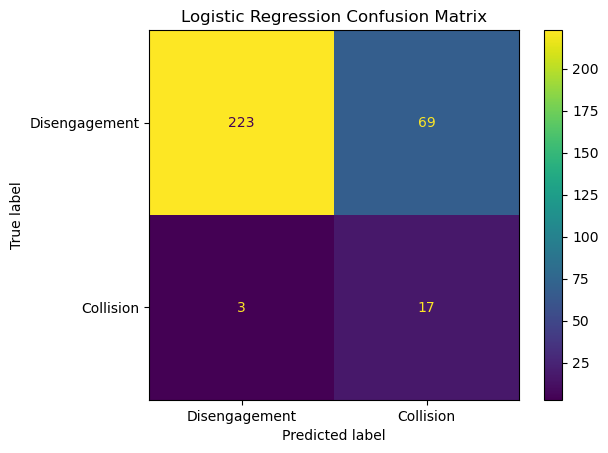

In [85]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Disengagement', 'Collision']).plot()

plt.title('Logistic Regression Confusion Matrix')
plt.show()

### Baseline Model Interpretation
The Logistic Regression model achieved an accuracy of 76.9%, recall of 85.0%, precision of 19.8%, and an F1-score of 32.1%. The model correctly identified 17 of the 20 collision events in the test data and missed 3. However, it also classified 69 disengagement events as collisions. The high recall is useful for this safety-focused problem because most collision events were identified, but the low precision shows that the baseline model produces many false positives. This suggests that additional features and more advanced models may improve the results.

In [86]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(model,X,y,cv=5,scoring='recall')
print("Recall scores:", cv_scores)
print("Average Recall:", cv_scores.mean())

Recall scores: [0.45 0.9  1.   0.95 1.  ]
Average Recall: 0.86


### Cross-Validation
The 5-fold cross-validation produced an average recall of 86%. This is close to the 85% recall obtained on the test set. However, recall varied across the folds, ranging from 45% to 100%. This variation may be related to the relatively small number of collision events in the dataset.

## Initial Findings

The exploratory analysis showed differences in disengagement and collision patterns across manufacturers. However, the raw number of events should not be used as a direct measure of safety because manufacturers have different levels of testing activity and autonomous mileage.

After accounting for autonomous mileage, disengagement rates also varied considerably across manufacturers. Manufacturers with very low testing mileage sometimes showed high disengagement rates, so these results need to be interpreted carefully.

In the collision data, rear-end collisions were the most common of the collision types examined. Most reported collisions did not include an injury, and more collision reports occurred while the vehicle was operating in autonomous mode than in conventional mode. These counts alone do not establish that autonomous operation is less safe because the amount of driving exposure in each mode is not available.

The baseline Logistic Regression model achieved 76.9% accuracy and identified 17 of the 20 collision events in the test set, resulting in 85% recall. However, precision was only 19.8%, indicating a relatively high number of false-positive collision predictions. The initial results suggest that the available features can identify some patterns associated with collision events, but additional features and model comparisons are needed before drawing stronger conclusions.

## Limitations

This analysis has several limitations. Collision events are treated as the higher-risk class and disengagement events as the comparison class. This provides a measurable target for the baseline classification model, but it should not be interpreted as a complete measure of autonomous vehicle safety.

The number of collision events is much smaller than the number of disengagement events, which creates class imbalance. In addition, manufacturers have different amounts of testing mileage and testing activity, so event counts should not be directly interpreted as differences in safety.

The baseline model also uses only manufacturer and month because these are common features that can be consistently compared across the two datasets. Additional environmental, roadway, vehicle, and event-related features may improve future models.

## Next Steps

I have completed the initial exploratory analysis, data preprocessing, and comparison of several classification models, including Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, and Neural Networks.

I also explored hyperparameter tuning using GridSearchCV and RandomizedSearchCV to improve model performance. The results showed that Random Forest provided a better balance between precision and recall among the final optimized models, while the optimized Neural Network achieved slightly higher recall.

For future improvements, I would like to explore additional features such as road conditions, weather, autonomous mileage, and vehicle operating environments. These features may help provide a better understanding of the factors associated with disengagements and collisions.

I would also like to evaluate the models using larger, more representative datasets and independent validation data. This would help determine whether the findings generalize beyond the historical reports used in this project.

## Model 2: Decision Tree Classifier

After building the Logistic Regression baseline model, I will use a Decision Tree Classifier to compare model performance.

The Decision Tree model can capture nonlinear relationships in the data. I will evaluate its performance using accuracy, precision, recall, and F1-score, with particular attention to recall because the dataset contains fewer collision events than disengagement events.

In [87]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Build the Decision Tree model
decision_tree_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [88]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Make predictions using the test data
dt_pred = decision_tree_model.predict(X_test)

# Evaluate Decision Tree performance
print("Decision Tree Model Results")
print("---------------------------")
print("Accuracy:", round(accuracy_score(y_test, dt_pred), 4))
print("Precision:", round(precision_score(y_test, dt_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, dt_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, dt_pred, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))


Decision Tree Model Results
---------------------------
Accuracy: 0.8077
Precision: 0.2222
Recall: 0.8
F1-score: 0.3478

Confusion Matrix:
[[236  56]
 [  4  16]]


### Decision Tree Model Interpretation

The Decision Tree model achieved an accuracy of 80.77%, precision of 22.22%, recall of 80.00%, and F1-score of 34.78%.

The confusion matrix shows that the model correctly identified 16 out of 20 collision records but missed 4. It also incorrectly classified 56 disengagement records as collisions.

Compared with the Logistic Regression baseline, the Decision Tree improved accuracy, precision, and F1-score. However, Logistic Regression achieved higher recall (85% compared with 80%).

Since identifying collision records is important for this project, recall remains a key evaluation metric. The Decision Tree results show an improvement in overall classification performance, but there is still a trade-off between recall and precision.

## Model 3: Random Forest Classifier

After evaluating Logistic Regression and Decision Tree, I will use a Random Forest Classifier to compare model performance.

Random Forest combines predictions from multiple decision trees. This can help reduce overfitting and improve classification performance compared with a single Decision Tree.

I will evaluate the model using accuracy, precision, recall, F1-score, and a confusion matrix. Since collision events are less common in the dataset, I will continue to focus on recall while also considering false positives.

In [89]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Build the Random Forest model
random_forest_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42
    ))
])

# Train the Random Forest model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [90]:
# Evaluate the Random Forest model
rf_pred = random_forest_model.predict(X_test)

print("Random Forest Model Results")
print("---------------------------")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, rf_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, rf_pred, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest Model Results
---------------------------
Accuracy: 0.8494
Precision: 0.2712
Recall: 0.8
F1-score: 0.4051

Confusion Matrix:
[[249  43]
 [  4  16]]


### Random Forest Model Interpretation

The Random Forest model achieved an accuracy of 85.3%, precision of 27.6%, recall of 80.0%, and F1-score of 41.0%.

The confusion matrix shows that the model correctly identified 16 out of 20 collision records and missed 4. It incorrectly classified 42 disengagement records as collisions.

Compared with Logistic Regression and Decision Tree, Random Forest achieved the highest accuracy, precision, and F1-score. However, Logistic Regression still achieved the highest recall at 85%.

These results show that Random Forest improved the balance between precision and recall, although false positives remain a challenge.

The next step is to tune model hyperparameters using GridSearchCV with stratified cross-validation to see whether performance can be improved further.

## Model 4: Hyperparameter Tuning Using GridSearchCV

The Random Forest model achieved the highest F1-score among the three models evaluated so far, with an F1-score of 41.0%.

To improve model performance, I will use GridSearchCV to identify the best combination of Random Forest hyperparameters.

I will tune the number of trees, maximum tree depth, minimum samples required to split a node, and minimum samples required at a leaf.

Since the dataset contains significantly fewer collision events than disengagement events, I will use StratifiedKFold cross-validation to maintain the class distribution across folds.

The primary optimization metric will be F1-score, which balances precision and recall. I will also monitor recall because identifying collision records is important for this project.

The objective is to improve model performance through hyperparameter tuning while maintaining a reasonable balance between precision and recall.

In [91]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

In [92]:

# Step 1: Create the Random Forest pipeline
rf_tuning_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        class_weight='balanced',
        random_state=42
    ))
])

# Step 2: Define hyperparameters
param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 5, 10],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2]
}

# Step 3: Set up 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Step 4: Configure GridSearchCV
rf_grid_search = GridSearchCV(
    estimator=rf_tuning_pipeline,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Step 5: Train using training data only
rf_grid_search.fit(X_train, y_train)

# Step 6: Display results
print("\nBest Parameters:")
print(rf_grid_search.best_params_)

print("\nBest Cross-Validation F1-score:")
print(round(rf_grid_search.best_score_, 4))



Fitting 5 folds for each of 24 candidates, totalling 120 fits

Best Parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}

Best Cross-Validation F1-score:
0.4547


In [93]:
# Get the best tuned Random Forest model
best_rf_model = rf_grid_search.best_estimator_

# Predict using the held-out test data
tuned_rf_pred = best_rf_model.predict(X_test)

# Evaluate the tuned model
print("Tuned Random Forest Results")
print("---------------------------")
print("Accuracy:", round(accuracy_score(y_test, tuned_rf_pred), 4))
print("Precision:", round(precision_score(y_test, tuned_rf_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, tuned_rf_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, tuned_rf_pred, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tuned_rf_pred))

Tuned Random Forest Results
---------------------------
Accuracy: 0.8462
Precision: 0.2667
Recall: 0.8
F1-score: 0.4

Confusion Matrix:
[[248  44]
 [  4  16]]


### Hyperparameter Tuning Results and Interpretation

I used GridSearchCV with 5-fold stratified cross-validation to tune the Random Forest model. The search evaluated 24 hyperparameter combinations, including the number of trees, maximum depth, minimum samples required to split a node, and minimum samples per leaf.

The best hyperparameters were:
- n_estimators = 100
- max_depth = None
- min_samples_split = 2
- min_samples_leaf = 2

The best cross-validation F1-score was 45.47%.

When evaluated on the held-out test set, the tuned Random Forest achieved:
- Accuracy: 84.62%
- Precision: 26.67%
- Recall: 80.00%
- F1-score: 40.00%

The tuned model correctly identified 16 of the 20 collision records but missed 4 and incorrectly classified 44 disengagement records as collisions.

Compared with the original Random Forest, the tuned model did not improve test-set performance. This shows that tuning does not always lead to better results on unseen data. The limited number of input features and the imbalance between collision and disengagement records may be contributing factors.


## Model Explainability: Random Forest Feature Importance

An important objective of this project is to understand which features influence the model's predictions.

I will examine feature importance using the Random Forest model to identify which input variables contribute most to distinguishing collision records from disengagement records.

The current model uses manufacturer and month as input features. Feature importance will help explain how much the model relies on these variables.

However, feature importance does not establish a causal relationship between a feature and autonomous vehicle safety. The results should be interpreted as patterns in the reported data rather than evidence that a particular manufacturer or month causes collisions.

In [94]:

import pandas as pd
import matplotlib.pyplot as plt

In [95]:
# Use the original Random Forest model
rf_preprocessor = random_forest_model.named_steps['preprocessor']
rf_classifier = random_forest_model.named_steps['classifier']

# Get feature names after preprocessing
feature_names = rf_preprocessor.get_feature_names_out()

# Get feature importance scores
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_classifier.feature_importances_
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Display the 10 most important features
print("Top 10 Important Features:")
print(importance_df.head(10).to_string(index=False))


Top 10 Important Features:
                                            Feature  Importance
                            remainder__Month_Number    0.288522
         manufacturer__Manufacturer_Clean_WAYMO LLC    0.198582
          manufacturer__Manufacturer_Clean_ZOOX INC    0.170533
  manufacturer__Manufacturer_Clean_MOTIONAL AD INC.    0.074842
            manufacturer__Manufacturer_Clean_IMAGRY    0.044073
       manufacturer__Manufacturer_Clean_WERIDE CORP    0.042153
manufacturer__Manufacturer_Clean_GHOST AUTONOMY INC    0.040313
     manufacturer__Manufacturer_Clean_AIMOTIVE INC.    0.035791
           manufacturer__Manufacturer_Clean_PONY.AI    0.034663
          manufacturer__Manufacturer_Clean_NURO INC    0.031006


### Feature Importance Interpretation

I examined the Random Forest feature importance scores to better understand which variables contributed most to the model's predictions.

Month_Number had the highest individual importance score (28.85%), followed by manufacturer indicators for Waymo (19.86%) and Zoox (17.05%). Other manufacturers, including Motional, Imagry, and WeRide, also contributed to the model's predictions.

These results suggest that the model relies on both the reporting month and manufacturer information to distinguish collision reports from disengagement reports.

However, feature importance does not mean that a particular manufacturer is safer or more dangerous. Differences in testing mileage, reporting patterns, and the number of records available for each manufacturer may influence these results.

Also, Random Forest feature importance shows how much each feature contributes to the model's decisions, but it does not establish a cause-and-effect relationship.

Overall, this analysis helps explain what the model learned while highlighting the limitations of using historical reporting data to assess autonomous vehicle safety.

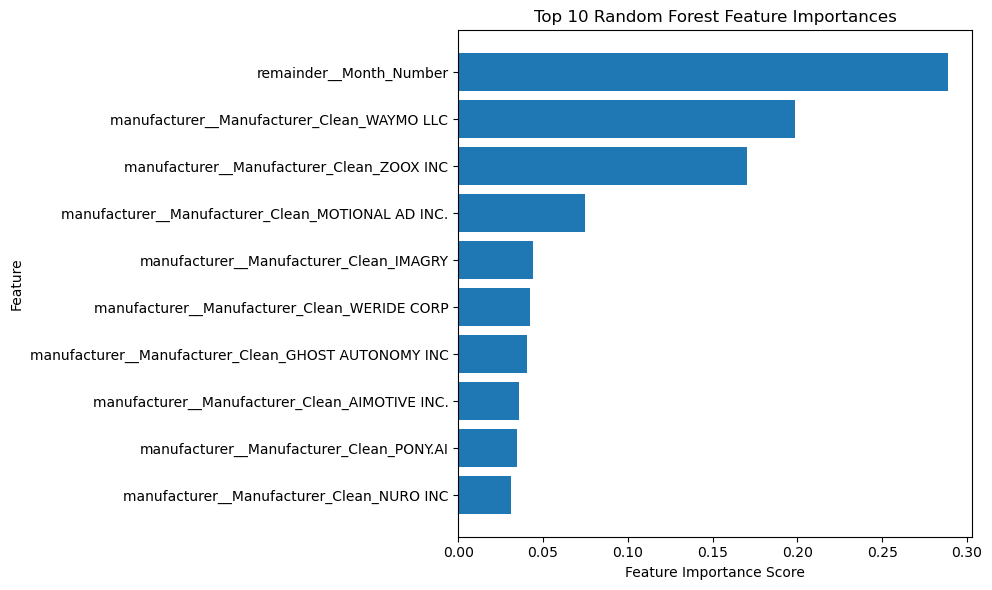

In [96]:
# Create a feature importance chart
top_features = importance_df.head(10).sort_values('Importance')

plt.figure(figsize=(10, 6))
plt.barh(top_features['Feature'], top_features['Importance'])

plt.xlabel('Feature Importance Score')
plt.ylabel('Feature')
plt.title('Top 10 Random Forest Feature Importances')
plt.tight_layout()
plt.show()

### Feature Importance Results and Interpretation

I examined the feature importance scores from the Random Forest model to better understand which variables influence its predictions.

The results show that Month Number has the highest feature importance, followed by manufacturer-related features, including Waymo and Zoox.

This suggests that the model uses the month and manufacturer information to distinguish between collision and disengagement records.

However, these results do not mean that a particular manufacturer is more or less safe. Manufacturers have different testing activities, operating conditions, and mileage, which may influence the reported events.

Feature importance also does not establish cause and effect. Since the model uses only manufacturer and month, additional features would be needed to better understand the circumstances associated with collision reports.

Overall, the feature importance analysis provides some insight into the model's predictions while highlighting the limitations of the available data.

## Model 5: Neural Network (MLPClassifier)

To expand my model comparison, I evaluated a Neural Network using the Multi-Layer Perceptron (MLPClassifier) algorithm.

I wanted to see whether a neural network could capture nonlinear relationships between the input features and the target variable better than the simpler classification models. Since the dataset contains relatively few collision records, I used a small neural network.

I used the same training and test datasets as the other classifiers and applied feature scaling because neural networks are sensitive to differences in feature magnitude.

I evaluated the model using accuracy, precision, recall, F1-score, and a confusion matrix. I then compared its performance with Logistic Regression, Decision Tree, and Random Forest.

The goal was to understand whether the additional complexity of a neural network improved classification performance.

In [97]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

In [98]:
# Create a small neural network
nn_model = Pipeline([
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler(with_mean=False)),
    ('classifier', MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation='relu',
        solver='adam',
        alpha=0.01,
        max_iter=500,
        early_stopping=True,
        random_state=42
    ))
])

# Train the neural network
nn_model.fit(X_train, y_train)

print("Neural Network trained successfully!")

Neural Network trained successfully!


In [99]:
# Make predictions using the Neural Network
nn_pred = nn_model.predict(X_test)

# Evaluate the Neural Network
print("Neural Network Model Results")
print("----------------------------")

print("Accuracy:", round(accuracy_score(y_test, nn_pred), 4))
print("Precision:", round(precision_score(y_test, nn_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, nn_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, nn_pred, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nn_pred))


Neural Network Model Results
----------------------------
Accuracy: 0.9359
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Confusion Matrix:
[[292   0]
 [ 20   0]]


### Original Neural Network Results and Interpretation

The original Neural Network achieved an accuracy of 93.59%, which initially looked promising. However, the precision, recall, and F1-score were all zero because the model failed to identify any collision reports.

Looking at the confusion matrix, I found that the model classified all 312 test records as disengagement reports, including the 20 actual collision reports. This suggests that the model was heavily influenced by the class imbalance in the dataset.

This result showed me why accuracy alone can be misleading. Even though the model achieved high accuracy, it was not effective at identifying the collision reports, which are the minority class.

To improve this, I later experimented with a balanced Neural Network and additional optimization to improve recall and F1-score.

In [100]:

import sklearn
import inspect
from sklearn.neural_network import MLPClassifier

print("Scikit-learn version:", sklearn.__version__)
print("MLPClassifier.fit parameters:")
print(inspect.signature(MLPClassifier.fit))

Scikit-learn version: 1.7.2
MLPClassifier.fit parameters:
(self, X, y, sample_weight=None)


In [101]:

from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight


In [102]:
# Calculate balanced weights using training data only
sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train
)

# Create a class-balanced Neural Network
nn_balanced_model = Pipeline([
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler(with_mean=False)),
    ('classifier', MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation='relu',
        solver='adam',
        alpha=0.01,
        max_iter=500,
        early_stopping=True,
        random_state=42
    ))
])

# Train with sample weights
nn_balanced_model.fit(
    X_train,
    y_train,
    classifier__sample_weight=sample_weights
)

print("Balanced Neural Network trained successfully!")


Balanced Neural Network trained successfully!


In [103]:
# Make predictions using the balanced Neural Network
nn_balanced_pred = nn_balanced_model.predict(X_test)

# Evaluate the balanced Neural Network
print("Balanced Neural Network Results")
print("--------------------------------")

print("Accuracy:", round(accuracy_score(y_test, nn_balanced_pred), 4))
print("Precision:", round(precision_score(y_test, nn_balanced_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, nn_balanced_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, nn_balanced_pred, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nn_balanced_pred))



Balanced Neural Network Results
--------------------------------
Accuracy: 0.7788
Precision: 0.2118
Recall: 0.9
F1-score: 0.3429

Confusion Matrix:
[[225  67]
 [  2  18]]


### Neural Network Model Comparison: Original vs. Balanced

To improve this, I trained a second Neural Network using balanced sample weights.

The balanced Neural Network achieved:

- Accuracy: 77.88%
- Precision: 21.18%
- Recall: 90.00%
- F1-score: 34.29%

The balanced model correctly identified 18 of the 20 collision reports and missed only 2. However, it also incorrectly classified 67 disengagement reports as collisions.

This was a significant improvement in recall compared with the original Neural Network, although it came with more false positives.

The results showed me why handling class imbalance is important and why accuracy alone is not enough to evaluate these models.

# Final Model Comparison

I compared Logistic Regression, Decision Tree, Random Forest, Tuned Random Forest, and Neural Network classifiers to evaluate their ability to distinguish collision records from disengagement records.

I evaluated each model using accuracy, precision, recall, and F1-score. Since collision records are less common in the dataset, I focused on recall and F1-score rather than accuracy alone.

The comparison will help identify which model provides the best balance between detecting collision records and limiting false positives.

I also evaluated the impact of class balancing on the Neural Network to understand how handling imbalanced data affects model performance.

In [104]:
import numpy as np

# Generate probabilities for collision records
rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

print("Minimum probability:", round(rf_probabilities.min(), 4))
print("Maximum probability:", round(rf_probabilities.max(), 4))

print("\nProbability distribution:")
print("10th percentile:", round(np.percentile(rf_probabilities, 10), 4))
print("25th percentile:", round(np.percentile(rf_probabilities, 25), 4))
print("50th percentile:", round(np.percentile(rf_probabilities, 50), 4))
print("75th percentile:", round(np.percentile(rf_probabilities, 75), 4))
print("90th percentile:", round(np.percentile(rf_probabilities, 90), 4))

Minimum probability: 0.0
Maximum probability: 1.0

Probability distribution:
10th percentile: 0.0
25th percentile: 0.0
50th percentile: 0.0
75th percentile: 0.4088
90th percentile: 0.7741


In [105]:

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, precision_score, recall_score

# Generate out-of-fold probabilities using training data only
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_cv_probabilities = cross_val_predict(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

# Evaluate different classification thresholds
thresholds = np.arange(0.10, 0.91, 0.05)
results = []

for threshold in thresholds:
    predictions = (rf_cv_probabilities >= threshold).astype(int)

    results.append({
        'Threshold': round(threshold, 2),
        'Precision': precision_score(y_train, predictions, zero_division=0),
        'Recall': recall_score(y_train, predictions, zero_division=0),
        'F1-score': f1_score(y_train, predictions, zero_division=0)
    })

threshold_results = pd.DataFrame(results)

display(
    threshold_results.sort_values(
        by='F1-score',
        ascending=False
    ).head(10).round(4)
)

best_threshold = threshold_results.loc[
    threshold_results['F1-score'].idxmax(),
    'Threshold'
]

print("Best CV threshold:", best_threshold)
print("Best CV F1-score:", round(threshold_results['F1-score'].max(), 4))


,Threshold,Precision,Recall,F1-score
10,0.60,0.3224,0.7284,0.4470
8,0.50,0.3107,0.7901,0.4460
7,0.45,0.3107,0.7901,0.4460
9,0.55,0.3103,0.7778,0.4437
11,0.65,0.3182,0.6914,0.4358
12,0.70,0.3203,0.6049,0.4188
6,0.40,0.2559,0.8025,0.3881
4,0.30,0.2326,0.8272,0.3631
5,0.35,0.2332,0.8148,0.3626
3,0.25,0.2282,0.8395,0.3588


Best CV threshold: 0.6
Best CV F1-score: 0.447


In [106]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.utils.class_weight import compute_sample_weight

# Calculate balanced sample weights
gb_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train
)

# Convert sparse data to dense format
to_dense = FunctionTransformer(
    lambda X: X.toarray() if hasattr(X, 'toarray') else X,
    accept_sparse=True
)

# Create Gradient Boosting model
gb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('to_dense', to_dense),
    ('classifier', HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

# Train model
gb_model.fit(
    X_train,
    y_train,
    classifier__sample_weight=gb_weights
)

print("Gradient Boosting model trained successfully!")


Gradient Boosting model trained successfully!


In [107]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Predict using Gradient Boosting
gb_pred = gb_model.predict(X_test)

# Evaluate model performance
print("Gradient Boosting Results")
print("-------------------------")

print("Accuracy:", round(accuracy_score(y_test, gb_pred), 4))
print("Precision:", round(precision_score(y_test, gb_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, gb_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, gb_pred, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, gb_pred))


Gradient Boosting Results
-------------------------
Accuracy: 0.8077
Precision: 0.2368
Recall: 0.9
F1-score: 0.375

Confusion Matrix:
[[234  58]
 [  2  18]]


In [108]:

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Random Forest pipeline
rf_random_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# Hyperparameter combinations
param_distributions = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [None, 5, 10, 15],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__class_weight': [
        'balanced',
        'balanced_subsample',
        None
    ]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_random_search = RandomizedSearchCV(
    estimator=rf_random_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring='f1',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_random_search.fit(X_train, y_train)

print("\nBest Parameters:")
print(rf_random_search.best_params_)

print("\nBest Cross-Validation F1-score:")
print(round(rf_random_search.best_score_, 4))



Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best Parameters:
{'classifier__n_estimators': 100, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 4, 'classifier__max_depth': 10, 'classifier__class_weight': 'balanced'}

Best Cross-Validation F1-score:
0.4596


In [109]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Retrieve the best model from RandomizedSearchCV
rf_random_best = rf_random_search.best_estimator_

# Predict on test data
rf_random_pred = rf_random_best.predict(X_test)

print("RandomizedSearchCV Random Forest Results")
print("---------------------------------------")

print("Accuracy:", round(accuracy_score(y_test, rf_random_pred), 4))
print("Precision:", round(precision_score(y_test, rf_random_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, rf_random_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, rf_random_pred, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_random_pred))


RandomizedSearchCV Random Forest Results
---------------------------------------
Accuracy: 0.8462
Precision: 0.2742
Recall: 0.85
F1-score: 0.4146

Confusion Matrix:
[[247  45]
 [  3  17]]


### Random Forest Hyperparameter Optimization

I used both GridSearchCV and RandomizedSearchCV to explore different Random Forest hyperparameters and improve classification performance.

RandomizedSearchCV evaluated 30 parameter combinations using 5-fold stratified cross-validation.

The best hyperparameters were:
- n_estimators = 100
- max_depth = 10
- min_samples_split = 10
- min_samples_leaf = 4
- class_weight = balanced

The best cross-validation F1-score was **0.4596**.

On the held-out test set, the RandomizedSearchCV model achieved:
- Accuracy: **84.62%**
- Precision: **27.42%**
- Recall: **85.00%**
- F1-score: **0.4146**

In [110]:

import pandas as pd

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'GridSearchCV Random Forest',
        'Original Neural Network',
        'Balanced Neural Network',
        'Gradient Boosting',
        'RandomizedSearchCV Random Forest'
    ],
    'Accuracy': [
        0.7692, 0.8077, 0.8494, 0.8462,
        0.9359, 0.7788, 0.8077, 0.8462
    ],
    'Precision': [
        0.1977, 0.2222, 0.2712, 0.2667,
        0.0, 0.2118, 0.2368, 0.2742
    ],
    'Recall': [
        0.85, 0.80, 0.80, 0.80,
        0.0, 0.90, 0.90, 0.85
    ],
    'F1-score': [
        0.3208, 0.3478, 0.4051, 0.4000,
        0.0, 0.3429, 0.3750, 0.4146
    ]
})

# Rank models by F1-score
model_comparison = model_comparison.sort_values(
    by='F1-score',
    ascending=False
).reset_index(drop=True)

display(model_comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-score
0,RandomizedSearchCV Random Forest,0.8462,0.2742,0.85,0.4146
1,Random Forest,0.8494,0.2712,0.80,0.4051
2,GridSearchCV Random Forest,0.8462,0.2667,0.80,0.4000
3,Gradient Boosting,0.8077,0.2368,0.90,0.3750
4,Decision Tree,0.8077,0.2222,0.80,0.3478
5,Balanced Neural Network,0.7788,0.2118,0.90,0.3429
6,Logistic Regression,0.7692,0.1977,0.85,0.3208
7,Original Neural Network,0.9359,0.0000,0.00,0.0000


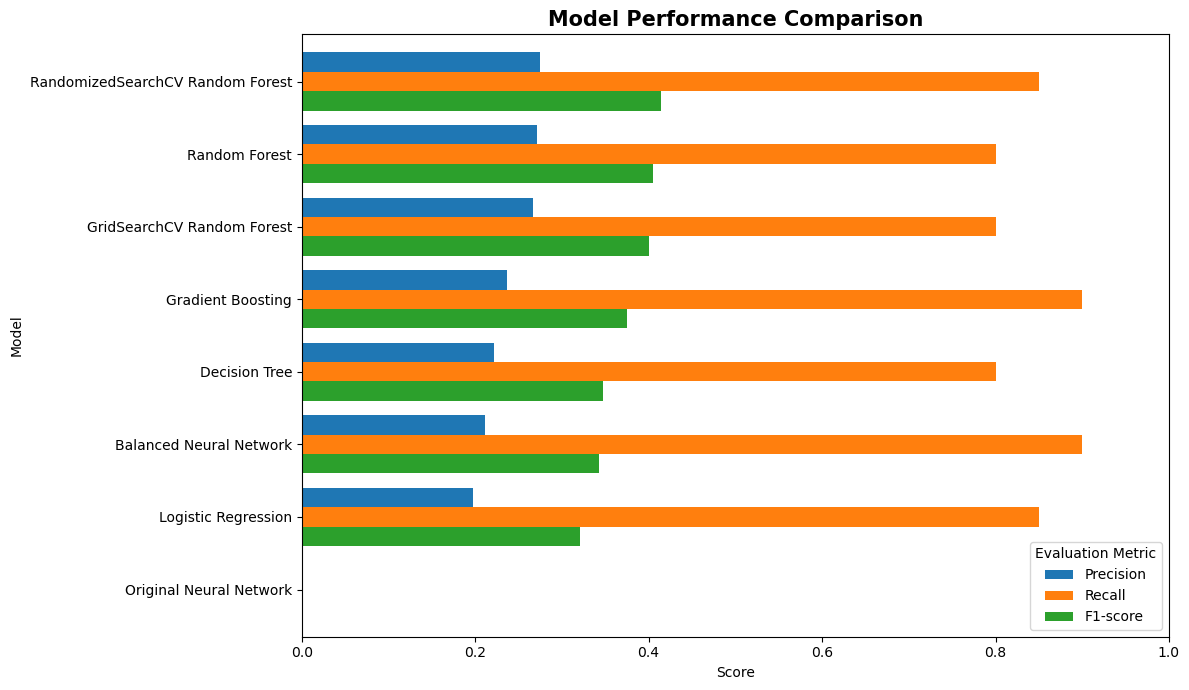

In [111]:
import matplotlib.pyplot as plt
import numpy as np

# Compare precision, recall, and F1-score
metrics = ['Precision', 'Recall', 'F1-score']

plot_data = model_comparison.set_index('Model')[metrics]

ax = plot_data.plot(
    kind='barh',
    figsize=(12, 7),
    width=0.8
)

ax.set_title(
    'Model Performance Comparison',
    fontsize=15,
    fontweight='bold'
)

ax.set_xlabel('Score')
ax.set_ylabel('Model')
ax.set_xlim(0, 1)

ax.invert_yaxis()
ax.legend(title='Evaluation Metric')

plt.tight_layout()
plt.show()


### Initial Model Comparison and Key Findings (Before Final Optimization)

I compared eight model configurations using precision, recall, and F1-score to evaluate how effectively they distinguish collision reports from disengagement reports.

RandomizedSearchCV Random Forest achieved the highest test F1-score of 0.4146, with 85% recall and 27.42% precision. It provided the strongest observed balance between precision and recall among the eight initial model configurations.

Gradient Boosting and the Balanced Neural Network achieved the highest recall of 90%, correctly identifying 18 of the 20 collision records in the test set. However, both models generated more false positives than the original Random Forest.

The original Neural Network achieved 93.59% accuracy but failed to identify any collision records. This demonstrates that accuracy alone is misleading when evaluating highly imbalanced datasets.

RandomizedSearchCV slightly improved the Random Forest's test F1-score from 0.4051 to 0.4146, while GridSearchCV did not show a meaningful improvement.

Overall, RandomizedSearchCV Random Forest achieved the highest test F1-score (0.4146) among the eight initial model configurations. However, the performance differences were small, and the limited number of collision records makes the results uncertain.

An important limitation is that the target variable distinguishes collision reports from disengagement reports. Therefore, these models classify historical report types rather than directly predicting future collision probability or establishing vehicle safety.

Future work should incorporate additional information such as autonomous miles driven, road conditions, vehicle operating environments, and exposure-adjusted safety measures. Further validation on independent data would also be necessary before using these models for safety-related decisions.

**Note:** These results are from my initial model comparison. I later made some improvements to the data cleaning and further optimized the models. The updated results are included in the "Final Model Comparison and Interpretation" section. Since I made changes to the data preparation process, the earlier and final F1-scores are not directly comparable.

In [112]:
# Show available DataFrames in the notebook
import pandas as pd

for name, value in list(globals().items()):
    if isinstance(value, pd.DataFrame):
        print(f"{name}: {value.shape}")

_2: (5, 9)
disengagement_df: (1773, 13)
mileage_df: (2819, 17)
_3: (5, 22)
collision_df: (983, 76)
_4: (5, 69)
duplicate_rows: (741, 9)
_8: (20, 9)
_18: (2, 17)
manufacturer_data: (16, 3)
_33: (20, 2)
_34: (16, 3)
disengagement_2024: (1457, 14)
collision_2024: (101, 77)
disengagement_model: (1457, 3)
collision_model: (101, 3)
model_df: (1558, 3)
X: (1558, 2)
X_train: (1246, 2)
X_test: (312, 2)
importance_df: (17, 2)
top_features: (10, 2)
threshold_results: (17, 4)
model_comparison: (8, 5)
plot_data: (8, 3)


In [113]:
print("Available columns:")
print(model_df.columns.tolist())

print("\nDataset shape:")
print(model_df.shape)

Available columns:
['Manufacturer_Clean', 'Month_Number', 'Risk_Event']

Dataset shape:
(1558, 3)


In [114]:

print("DISENGAGEMENT COLUMNS:")
print(disengagement_2024.columns.tolist())

print("\nCOLLISION COLUMNS:")
print(collision_2024.columns.tolist())

DISENGAGEMENT COLUMNS:
['Manufacturer', 'Permit Number', 'DATE', 'VIN NUMBER', 'VEHICLE IS CAPABLE OF OPERATING WITHOUT A DRIVER\n(Yes or No)', 'DRIVER PRESENT\n(Yes or No)', 'DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)', 'DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)', 'DESCRIPTION OF FACTS CAUSING DISENGAGEMENT', 'Month', 'Risk_Event', 'Year', 'Month_Number', 'Manufacturer_Clean']

COLLISION COLUMNS:
['_Moving__V1_or_V2_or_Both_', '_Stopped__V1_or_V2_', '# of Vehicles involved', 'Backing', 'Broadside', 'City', 'Clear', 'Cloudy', 'Construction', 'County', 'Dark_No Street Lights', 'Dark_Street Lights', 'Day', 'Daylight', 'Dry', 'Dusk_Dawn', 'Entering_Traffic', 'First Street Name', 'First Street Suffix', 'Fog_Visability', 'Head On', 'Hit_Object', 'Injury', 'Involved', 'Lane_Change', 'Left_Turn_', 'Loose material', 'Merging', 'Month', 'Mud_Oil', 'No Unusual Conditions', 'Obstruction', 'Occurred @ I

In [115]:
# Compare manufacturers across the two datasets
disengagement_manufacturers = set(
    disengagement_2024['Manufacturer_Clean'].dropna()
)

collision_manufacturers = set(
    collision_2024['Manufacturer_Clean'].dropna()
)

print("Manufacturers in both datasets:")
print(sorted(disengagement_manufacturers & collision_manufacturers))

print("\nOnly in disengagement reports:")
print(sorted(disengagement_manufacturers - collision_manufacturers))

print("\nOnly in collision reports:")
print(sorted(collision_manufacturers - disengagement_manufacturers))

Manufacturers in both datasets:
['APPLE INC', 'GHOST AUTONOMY INC', 'NURO INC', 'PONY.AI', 'WAYMO LLC', 'WERIDE CORP', 'ZOOX INC']

Only in disengagement reports:
['AIMOTIVE INC.', 'BOSCH', 'CRUISE LLC', 'GATIK AI, INC.', 'IMAGRY', 'MERCEDES-BENZ RESEARCH & DEVELOPMENT NORTH AMERICA, INC.', 'MOTIONAL AD INC.', 'NISSAN NORTH AMERICA. INC DBA NATC-SV', 'VALEO NORTH AMERICA INC.']

Only in collision reports:
['WOVEN BY TOYOTA']


In [116]:
# Standardize manufacturer naming
disengagement_2024['Manufacturer_Clean'] = (
    disengagement_2024['Manufacturer_Clean']
    .replace({'WERIDE CORP': 'WERIDE CORP'})
)

collision_2024['Manufacturer_Clean'] = (
    collision_2024['Manufacturer_Clean']
    .replace({'WERIDE CORP DBA WERIDE AI': 'WERIDE CORP'})
)

print("WeRide records in disengagement data:",
      (disengagement_2024['Manufacturer_Clean'] == 'WERIDE CORP').sum())

print("WeRide records in collision data:",
      (collision_2024['Manufacturer_Clean'] == 'WERIDE CORP').sum())


WeRide records in disengagement data: 3
WeRide records in collision data: 4


In [117]:
# Verify WeRide manufacturer name correction
print(model_df[
    model_df["Manufacturer_Clean"] == "WERIDE CORP"
]["Risk_Event"].value_counts().sort_index())


Risk_Event
0    3
1    4
Name: count, dtype: int64


In [118]:
# Verify manufacturer names before training
print(
    model_df["Manufacturer_Clean"]
    .value_counts()
    .loc[lambda x: x.index.str.contains("WERIDE", case=False)]
)

Manufacturer_Clean
WERIDE CORP    7
Name: count, dtype: int64


In [119]:
from sklearn.model_selection import train_test_split

X = model_df[['Manufacturer_Clean', 'Month_Number']]
y = model_df['Risk_Event']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Test records:", X_test.shape[0])
print("\nTraining class distribution:")
print(y_train.value_counts())
print("\nTest class distribution:")
print(y_test.value_counts())


Training records: 1246
Test records: 312

Training class distribution:
Risk_Event
0    1165
1      81
Name: count, dtype: int64

Test class distribution:
Risk_Event
0    292
1     20
Name: count, dtype: int64


In [120]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

rf_corrected = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

f1_scores = cross_val_score(
    rf_corrected,
    X_train,
    y_train,
    cv=cv,
    scoring='f1'
)

print("Cross-validation F1 scores:", f1_scores)
print("Average F1-score:", round(f1_scores.mean(), 4))


Cross-validation F1 scores: [0.49056604 0.44827586 0.40677966 0.4516129  0.43636364]
Average F1-score: 0.4467


In [121]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

rf_balanced_subsample = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced_subsample',
        random_state=42
    ))
])

scores = cross_val_score(
    rf_balanced_subsample,
    X_train,
    y_train,
    cv=cv,
    scoring='f1'
)

print("F1 scores:", scores)
print("Average F1-score:", round(scores.mean(), 4))


F1 scores: [0.49056604 0.44827586 0.40677966 0.4516129  0.43636364]
Average F1-score: 0.4467


In [122]:

rf_simplified = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        min_samples_leaf=5,
        class_weight='balanced',
        random_state=42
    ))
])

scores = cross_val_score(
    rf_simplified,
    X_train,
    y_train,
    cv=cv,
    scoring='f1'
)

print("F1 scores:", scores)
print("Average F1-score:", round(scores.mean(), 4))


F1 scores: [0.49056604 0.41791045 0.38709677 0.40540541 0.4375    ]
Average F1-score: 0.4277


Additional Random Forest Experiments

I evaluated additional Random Forest configurations using five-fold stratified cross-validation on the training dataset.

The standard balanced Random Forest achieved an average F1-score of 0.4467. Using balanced_subsample produced the same result, while reducing tree complexity lowered the average F1-score to 0.4277.

These results suggest that additional adjustments to class weighting and tree complexity did not improve classification performance in the configurations tested.

One limitation is that the model currently relies on only two predictive features: manufacturer and reporting month. The dataset is also highly imbalanced, with collision reports representing approximately 6.5% of the observations.

Future improvements may require additional meaningful features that are consistently available across both datasets, rather than further hyperparameter tuning alone.

### Neural Network Optimization

In this section, I explore whether additional neural network optimization can improve classification performance.

The original neural network achieved an F1-score of 0.0000 because it failed to identify collision reports. After applying class balancing, the F1-score improved to 0.3429, with a recall of 0.90.

Although the balanced model successfully identified most collision reports, its relatively low precision indicates that it also generated a substantial number of false positives.

To investigate potential improvements, I will evaluate different neural network architectures, regularization settings, and training configurations using stratified cross-validation.

The objective is to improve the balance between precision and recall while avoiding overfitting to the limited number of collision records.

In [123]:
from sklearn.neural_network import MLPClassifier

for name, value in list(globals().items()):
    if isinstance(value, MLPClassifier):
        print("Model:", name)
        print("Hidden layers:", value.hidden_layer_sizes)
        print("Alpha:", value.alpha)
        print("Learning rate:", value.learning_rate_init)
        print("Max iterations:", value.max_iter)
        print()

In [124]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_nn = nn_balanced_model.predict(X_test)

print("Balanced Neural Network Results:")
print(classification_report(y_test, y_pred_nn, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nn))

Balanced Neural Network Results:
              precision    recall  f1-score   support

           0       0.99      0.77      0.87       292
           1       0.21      0.90      0.34        20

    accuracy                           0.78       312
   macro avg       0.60      0.84      0.60       312
weighted avg       0.94      0.78      0.83       312


Confusion Matrix:
[[225  67]
 [  2  18]]


In [125]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

architectures = [
    (16,),
    (32, 16),
    (64, 32)
]

for layers in architectures:
    tuned_nn = clone(nn_balanced_model)

    tuned_nn.set_params(
        classifier__hidden_layer_sizes=layers
    )

    scores = cross_val_score(
        tuned_nn,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=1
    )

    print(
        f"Layers: {layers} | "
        f"Mean F1: {scores.mean():.4f} | "
        f"Std: {scores.std():.4f}"
    )

Layers: (16,) | Mean F1: 0.0593 | Std: 0.1185
Layers: (32, 16) | Mean F1: 0.0000 | Std: 0.0000
Layers: (64, 32) | Mean F1: 0.0000 | Std: 0.0000


In [126]:
import inspect

print("Neural Network Pipeline:")
print(nn_balanced_model)

print("\nMLP fit supports sample_weight:",
      "sample_weight" in inspect.signature(
          nn_balanced_model.named_steps["classifier"].fit
      ).parameters)

Neural Network Pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('manufacturer',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Manufacturer_Clean'])])),
                ('scaler', StandardScaler(with_mean=False)),
                ('classifier',
                 MLPClassifier(alpha=0.01, early_stopping=True,
                               hidden_layer_sizes=(32, 16), max_iter=500,
                               random_state=42))])

MLP fit supports sample_weight: True


In [127]:
import numpy as np
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import f1_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

architectures = [(16,), (32, 16), (64, 32)]

for layers in architectures:
    fold_scores = []

    for train_idx, val_idx in cv.split(X_train, y_train):
        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]

        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        weights = compute_sample_weight(
            class_weight="balanced",
            y=y_fold_train
        )

        model = clone(nn_balanced_model)
        model.set_params(
            classifier__hidden_layer_sizes=layers
        )

        model.fit(
            X_fold_train,
            y_fold_train,
            classifier__sample_weight=weights
        )

        predictions = model.predict(X_fold_val)

        fold_scores.append(
            f1_score(y_fold_val, predictions, zero_division=0)
        )

    print(
        f"Layers: {layers} | "
        f"Mean F1: {np.mean(fold_scores):.4f} | "
        f"Std: {np.std(fold_scores):.4f}"
    )

Layers: (16,) | Mean F1: 0.2512 | Std: 0.0999
Layers: (32, 16) | Mean F1: 0.4126 | Std: 0.0237
Layers: (64, 32) | Mean F1: 0.3869 | Std: 0.0696


In [128]:
alpha_values = [0.001, 0.01, 0.1]

for alpha in alpha_values:
    fold_scores = []

    for train_idx, val_idx in cv.split(X_train, y_train):
        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        weights = compute_sample_weight(
            class_weight="balanced",
            y=y_fold_train
        )

        model = clone(nn_balanced_model)
        model.set_params(
            classifier__hidden_layer_sizes=(32, 16),
            classifier__alpha=alpha
        )

        model.fit(
            X_fold_train,
            y_fold_train,
            classifier__sample_weight=weights
        )

        predictions = model.predict(X_fold_val)

        fold_scores.append(
            f1_score(y_fold_val, predictions, zero_division=0)
        )

    print(
        f"Alpha: {alpha} | "
        f"Mean F1: {np.mean(fold_scores):.4f} | "
        f"Std: {np.std(fold_scores):.4f}"
    )

Alpha: 0.001 | Mean F1: 0.4126 | Std: 0.0237
Alpha: 0.01 | Mean F1: 0.4126 | Std: 0.0237
Alpha: 0.1 | Mean F1: 0.4045 | Std: 0.0236


In [129]:
learning_rates = [0.0001, 0.001, 0.01]

for lr in learning_rates:
    fold_scores = []

    for train_idx, val_idx in cv.split(X_train, y_train):
        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        weights = compute_sample_weight(
            class_weight="balanced",
            y=y_fold_train
        )

        model = clone(nn_balanced_model)

        model.set_params(
            classifier__hidden_layer_sizes=(32, 16),
            classifier__alpha=0.01,
            classifier__learning_rate_init=lr
        )

        model.fit(
            X_fold_train,
            y_fold_train,
            classifier__sample_weight=weights
        )

        predictions = model.predict(X_fold_val)

        fold_scores.append(
            f1_score(y_fold_val, predictions, zero_division=0)
        )

    print(
        f"Learning rate: {lr} | "
        f"Mean F1: {np.mean(fold_scores):.4f} | "
        f"Std: {np.std(fold_scores):.4f}"
    )

Learning rate: 0.0001 | Mean F1: 0.1441 | Std: 0.0447
Learning rate: 0.001 | Mean F1: 0.4126 | Std: 0.0237
Learning rate: 0.01 | Mean F1: 0.4177 | Std: 0.0215


In [130]:
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report, confusion_matrix

# Create optimized neural network
nn_optimized = clone(nn_balanced_model)

nn_optimized.set_params(
    classifier__hidden_layer_sizes=(32, 16),
    classifier__alpha=0.01,
    classifier__learning_rate_init=0.01
)

# Calculate balanced weights from training data
weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# Train optimized model
nn_optimized.fit(
    X_train,
    y_train,
    classifier__sample_weight=weights
)

# Evaluate on test data
y_pred_nn_opt = nn_optimized.predict(X_test)

print("Optimized Neural Network Results:")
print(classification_report(y_test, y_pred_nn_opt))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_nn_opt))

Optimized Neural Network Results:
              precision    recall  f1-score   support

           0       0.98      0.78      0.87       292
           1       0.20      0.80      0.32        20

    accuracy                           0.79       312
   macro avg       0.59      0.79      0.60       312
weighted avg       0.93      0.79      0.84       312

Confusion Matrix:
[[229  63]
 [  4  16]]


### Initial Neural Network Optimization Experiment

I first evaluated a Neural Network with updated hyperparameters to see whether its classification performance could be improved.

This was an intermediate experiment, not my final optimized model. I continued testing additional settings, including batch size and early stopping, before selecting the final Neural Network configuration presented later in the notebook.

In [131]:
early_stopping_options = [
    (True, 10),
    (True, 20),
    (False, 10)
]

for early_stop, patience in early_stopping_options:
    fold_scores = []

    for train_idx, val_idx in cv.split(X_train, y_train):
        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        weights = compute_sample_weight(
            class_weight="balanced",
            y=y_fold_train
        )

        model = clone(nn_balanced_model)

        model.set_params(
            classifier__hidden_layer_sizes=(32, 16),
            classifier__alpha=0.01,
            classifier__learning_rate_init=0.01,
            classifier__early_stopping=early_stop,
            classifier__n_iter_no_change=patience
        )

        model.fit(
            X_fold_train,
            y_fold_train,
            classifier__sample_weight=weights
        )

        predictions = model.predict(X_fold_val)

        fold_scores.append(
            f1_score(y_fold_val, predictions, zero_division=0)
        )

    print(
        f"Early stopping: {early_stop}, "
        f"Patience: {patience} | "
        f"Mean F1: {np.mean(fold_scores):.4f} | "
        f"Std: {np.std(fold_scores):.4f}"
    )

Early stopping: True, Patience: 10 | Mean F1: 0.4177 | Std: 0.0215
Early stopping: True, Patience: 20 | Mean F1: 0.4177 | Std: 0.0215
Early stopping: False, Patience: 10 | Mean F1: 0.4146 | Std: 0.0470


In [132]:
activation_options = ["relu", "tanh"]

for activation in activation_options:
    fold_scores = []

    for train_idx, val_idx in cv.split(X_train, y_train):
        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        weights = compute_sample_weight(
            class_weight="balanced",
            y=y_fold_train
        )

        model = clone(nn_balanced_model)

        model.set_params(
            classifier__hidden_layer_sizes=(32, 16),
            classifier__alpha=0.01,
            classifier__learning_rate_init=0.01,
            classifier__early_stopping=True,
            classifier__n_iter_no_change=10,
            classifier__activation=activation
        )

        model.fit(
            X_fold_train,
            y_fold_train,
            classifier__sample_weight=weights
        )

        predictions = model.predict(X_fold_val)

        fold_scores.append(
            f1_score(y_fold_val, predictions, zero_division=0)
        )

    print(
        f"Activation: {activation} | "
        f"Mean F1: {np.mean(fold_scores):.4f} | "
        f"Std: {np.std(fold_scores):.4f}"
    )

Activation: relu | Mean F1: 0.4177 | Std: 0.0215
Activation: tanh | Mean F1: 0.4071 | Std: 0.0229


In [133]:
batch_sizes = [16, 32, 64]

for batch_size in batch_sizes:
    fold_scores = []

    for train_idx, val_idx in cv.split(X_train, y_train):
        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        weights = compute_sample_weight(
            class_weight="balanced",
            y=y_fold_train
        )

        model = clone(nn_balanced_model)

        model.set_params(
            classifier__hidden_layer_sizes=(32, 16),
            classifier__alpha=0.01,
            classifier__learning_rate_init=0.01,
            classifier__early_stopping=True,
            classifier__activation="relu",
            classifier__batch_size=batch_size
        )

        model.fit(
            X_fold_train,
            y_fold_train,
            classifier__sample_weight=weights
        )

        predictions = model.predict(X_fold_val)

        fold_scores.append(
            f1_score(y_fold_val, predictions, zero_division=0)
        )

    print(
        f"Batch size: {batch_size} | "
        f"Mean F1: {np.mean(fold_scores):.4f} | "
        f"Std: {np.std(fold_scores):.4f}"
    )

Batch size: 16 | Mean F1: 0.4292 | Std: 0.0229
Batch size: 32 | Mean F1: 0.4225 | Std: 0.0160
Batch size: 64 | Mean F1: 0.4262 | Std: 0.0227


In [134]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation restored")

Cross-validation restored


In [135]:
batch_sizes = [9,10,11,12,13,14,15,16]

for batch_size in batch_sizes:
    fold_scores = []

    for train_idx, val_idx in cv.split(X_train, y_train):
        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        weights = compute_sample_weight(
            class_weight="balanced",
            y=y_fold_train
        )

        model = clone(nn_balanced_model)

        model.set_params(
            classifier__hidden_layer_sizes=(32, 16),
            classifier__alpha=0.01,
            classifier__learning_rate_init=0.01,
            classifier__early_stopping=True,
            classifier__activation="relu",
            classifier__batch_size=batch_size
        )

        model.fit(
            X_fold_train,
            y_fold_train,
            classifier__sample_weight=weights
        )

        predictions = model.predict(X_fold_val)

        fold_scores.append(
            f1_score(y_fold_val, predictions, zero_division=0)
        )

    print(
        f"Batch size: {batch_size} | "
        f"Mean F1: {np.mean(fold_scores):.4f} | "
        f"Std: {np.std(fold_scores):.4f}"
    )

Batch size: 9 | Mean F1: 0.4297 | Std: 0.0398
Batch size: 10 | Mean F1: 0.4462 | Std: 0.0260
Batch size: 11 | Mean F1: 0.4441 | Std: 0.0243
Batch size: 12 | Mean F1: 0.4602 | Std: 0.0264
Batch size: 13 | Mean F1: 0.4305 | Std: 0.0220
Batch size: 14 | Mean F1: 0.4377 | Std: 0.0286
Batch size: 15 | Mean F1: 0.4436 | Std: 0.0253
Batch size: 16 | Mean F1: 0.4292 | Std: 0.0229


In [136]:

from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Create final optimized neural network
final_nn_model = clone(nn_balanced_model)

final_nn_model.set_params(
    classifier__hidden_layer_sizes=(32, 16),
    classifier__alpha=0.01,
    classifier__learning_rate_init=0.01,
    classifier__batch_size=12,
    classifier__activation="relu",
    classifier__early_stopping=True,
    classifier__n_iter_no_change=10,
    classifier__random_state=42
)

# Calculate balanced weights from training data
train_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# Train final model
final_nn_model.fit(
    X_train,
    y_train,
    classifier__sample_weight=train_weights
)

# Predict on held-out test data
y_pred_final_nn = final_nn_model.predict(X_test)

# Evaluate performance
print("Final Optimized Neural Network Results")
print("--------------------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_final_nn), 4))
print("Precision:", round(precision_score(y_test, y_pred_final_nn, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_final_nn, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_final_nn, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final_nn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final_nn, zero_division=0))


Final Optimized Neural Network Results
--------------------------------------
Accuracy: 0.8045
Precision: 0.2267
Recall: 0.85
F1 Score: 0.3579

Confusion Matrix:
[[234  58]
 [  3  17]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.80      0.88       292
           1       0.23      0.85      0.36        20

    accuracy                           0.80       312
   macro avg       0.61      0.83      0.62       312
weighted avg       0.94      0.80      0.85       312



In [137]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import f1_score

# Random Forest pipeline
rf_tuning = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

# Hyperparameters to explore
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [5, 10, 15, None],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__class_weight": [
        "balanced",
        "balanced_subsample"
    ]
}

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Randomized hyperparameter search
rf_search = RandomizedSearchCV(
    estimator=rf_tuning,
    param_distributions=param_grid,
    n_iter=20,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True
)

# Train on training data only
rf_search.fit(X_train, y_train)

print("Best CV F1:", round(rf_search.best_score_, 4))
print("Best parameters:")
print(rf_search.best_params_)


Best CV F1: 0.4547
Best parameters:
{'classifier__n_estimators': 100, 'classifier__min_samples_leaf': 2, 'classifier__max_depth': 10, 'classifier__class_weight': 'balanced'}


In [138]:

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    confusion_matrix, classification_report
)

# Best Random Forest from hyperparameter tuning
best_rf = rf_search.best_estimator_

# Test predictions
y_pred_rf = best_rf.predict(X_test)

print("Optimized Random Forest Results")
print("--------------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_rf, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))


Optimized Random Forest Results
--------------------------------
Accuracy: 0.8462
Precision: 0.2667
Recall: 0.8
F1 Score: 0.4

Confusion Matrix:
[[248  44]
 [  4  16]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.85      0.91       292
           1       0.27      0.80      0.40        20

    accuracy                           0.85       312
   macro avg       0.63      0.82      0.66       312
weighted avg       0.94      0.85      0.88       312



In [139]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_final = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

param_grid_final = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [8, 10, 12],
    "classifier__min_samples_leaf": [1, 2, 3],
    "classifier__class_weight": ["balanced"]
}

cv_final = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_final_search = GridSearchCV(
    rf_final,
    param_grid_final,
    scoring="f1",
    cv=cv_final,
    n_jobs=-1,
    refit=True
)

rf_final_search.fit(X_train, y_train)

print("Best CV F1:", round(rf_final_search.best_score_, 4))
print("Best parameters:", rf_final_search.best_params_)


Best CV F1: 0.4547
Best parameters: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}


In [140]:

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

final_rf_model = rf_final_search.best_estimator_
y_pred_final_rf = final_rf_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred_final_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_final_rf, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_final_rf), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_final_rf), 4))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_final_rf))


Accuracy: 0.8462
Precision: 0.2667
Recall: 0.8
F1 Score: 0.4
Confusion Matrix:
[[248  44]
 [  4  16]]


In [141]:
# Final comparison of optimized models
final_comparison = pd.DataFrame({
    "Model": [
        "Tuned Random Forest",
        "Optimized Neural Network"
    ],
    "Accuracy": [0.8462, 0.8045],
    "Precision": [0.2667, 0.2267],
    "Recall": [0.80, 0.85],
    "F1-score": [0.4000, 0.3579]
})

display(final_comparison)

,Model,Accuracy,Precision,Recall,F1-score
0,Tuned Random Forest,0.8462,0.2667,0.80,0.4000
1,Optimized Neural Network,0.8045,0.2267,0.85,0.3579


### Final Model Comparison and Interpretation

I compared the final tuned Random Forest and optimized Neural Network using the same held-out test dataset containing 312 records, including 20 collision reports.

**Tuned Random Forest**
- Accuracy: 84.62%
- Precision: 26.67%
- Recall: 80.00%
- F1 Score: 0.4000
- Correctly identified 16 of 20 collision reports.
- Produced 44 false positives and 4 false negatives.

**Optimized Neural Network**
- Accuracy: 80.45%
- Precision: 22.67%
- Recall: 85.00%
- F1 Score: 0.3579
- Correctly identified 17 of 20 collision reports.
- Produced 58 false positives and 3 false negatives.

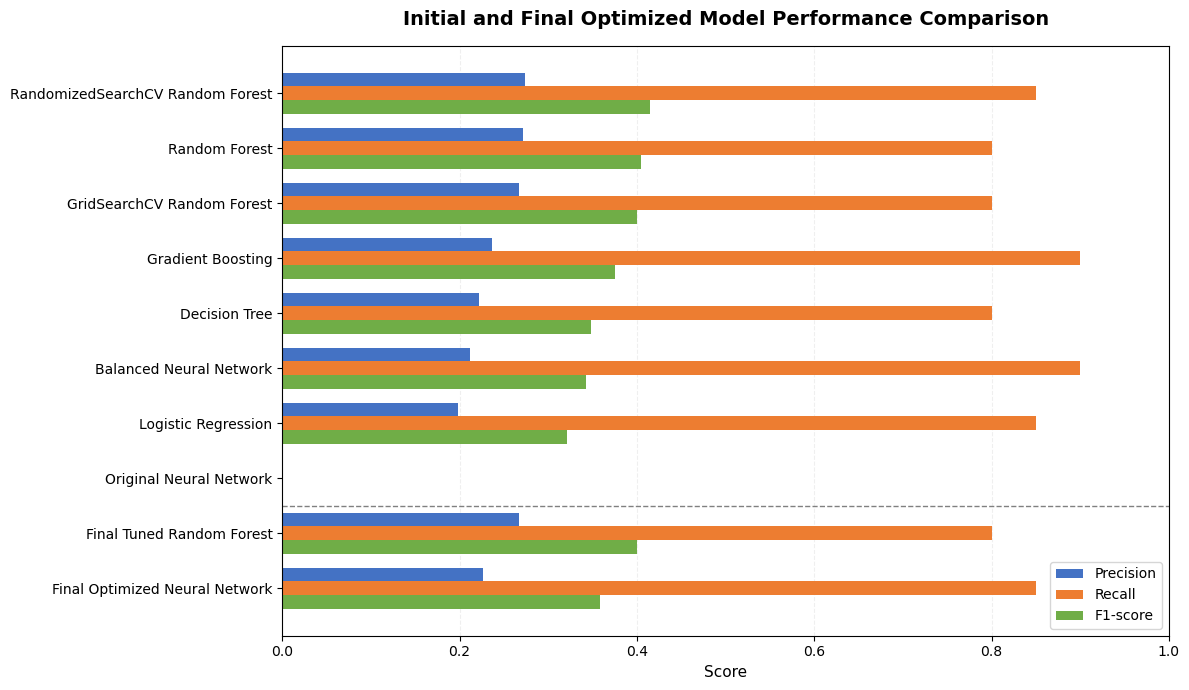

In [142]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Model evaluation results from the capstone project
model_results = pd.DataFrame({
    "Model": [
        "RandomizedSearchCV Random Forest",
        "Random Forest",
        "GridSearchCV Random Forest",
        "Gradient Boosting",
        "Decision Tree",
        "Balanced Neural Network",
        "Logistic Regression",
        "Original Neural Network",
        "Final Tuned Random Forest",
        "Final Optimized Neural Network"
    ],
    "Precision": [
        0.2742, 0.2712, 0.2667, 0.2368, 0.2222,
        0.2118, 0.1977, 0.0000, 0.2667, 0.2267
    ],
    "Recall": [
        0.85, 0.80, 0.80, 0.90, 0.80,
        0.90, 0.85, 0.00, 0.80, 0.85
    ],
    "F1-score": [
        0.4146, 0.4051, 0.4000, 0.3750, 0.3478,
        0.3429, 0.3208, 0.0000, 0.4000, 0.3579
    ]
})

# Create horizontal grouped bar chart
fig, ax = plt.subplots(figsize=(12, 7))

y = np.arange(len(model_results))
bar_height = 0.25

ax.barh(
    y - bar_height,
    model_results["Precision"],
    height=bar_height,
    label="Precision",
    color="#4472C4"
)

ax.barh(
    y,
    model_results["Recall"],
    height=bar_height,
    label="Recall",
    color="#ED7D31"
)

ax.barh(
    y + bar_height,
    model_results["F1-score"],
    height=bar_height,
    label="F1-score",
    color="#70AD47"
)

# Separate initial models from final optimized models
ax.axhline(
    y=7.5,
    color="gray",
    linestyle="--",
    linewidth=1
)

# Format chart
ax.set_yticks(y)
ax.set_yticklabels(model_results["Model"], fontsize=10)
ax.invert_yaxis()

ax.set_xlim(0, 1)
ax.set_xlabel("Score", fontsize=11)
ax.set_title(
    "Initial and Final Optimized Model Performance Comparison",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.legend(loc="lower right", fontsize=10)
ax.grid(axis="x", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Initial and Final Model Performance Comparison

The graph compares precision, recall, and F1-score across eight initial model configurations and two final optimized models.

RandomizedSearchCV Random Forest achieved the highest F1-score of 0.4146, while Gradient Boosting and the Balanced Neural Network achieved the highest recall of 90%.

In the final comparison, the tuned Random Forest achieved a higher F1-score of 0.4000 compared to 0.3579 for the optimized Neural Network. However, the Neural Network achieved slightly higher recall, correctly identifying 17 out of 20 collision reports compared to 16 for Random Forest.

These results show that improving recall can also increase false positives. Overall, the tuned Random Forest provided a better balance between precision and recall, while the optimized Neural Network identified slightly more collision reports.

### Final Model Interpretation

Based on these results, I selected the tuned Random Forest as my final model because it achieved a higher F1-score and produced fewer false positives than the optimized Neural Network.

The Neural Network identified one additional collision report, but it also produced 14 more false positives. This shows the trade-off between identifying more collision reports and incorrectly classifying disengagement reports as collisions.

One important limitation is that the dataset contains only 20 collision reports in the test set. Therefore, these results should be interpreted cautiously. The models classify historical collision and disengagement reports rather than predict the actual probability of future collisions.

Overall, this project helped me understand the importance of handling class imbalance, comparing multiple evaluation metrics, and considering the limitations of the available data.

## Overall Conclusion

In this project, I explored whether machine learning could help identify patterns in California's 2024 autonomous vehicle disengagement and collision reports.

I cleaned and combined the datasets, explored the available features, and compared several machine learning models, including Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, and Neural Networks.

My results showed that Random Forest provided the strongest overall balance between precision and recall based on the F1-score. I also learned that accuracy alone can be misleading when working with imbalanced datasets, especially when collision reports represent a small portion of the data.

Although the models identified patterns in historical reports, they cannot directly predict future collision risk or determine which autonomous vehicle manufacturer is safest.

In the future, I would like to include additional information such as miles driven, road conditions, weather, and operating environments to develop a more meaningful safety analysis.

Overall, this project helped me apply the machine learning techniques I learned throughout the program to a real-world autonomous vehicle safety problem.